# Семинары 9–10. ViT, CLIP, DETR и autoregressive models

**Две пары по 90 минут. Формат:** объяснение с нуля, затем полностью разобранные и исполняемые примеры. Код заранее написан; на занятии достаточно запускать ячейки по порядку, до запуска предсказывать результат и обсуждать вывод.

В предыдущих семинарах мы уже разобрали свёртки, детекцию, attention, Transformer encoder/decoder, positional encoding, causal mask и next-token prediction. Здесь мы не повторяем их с самого начала, а переносим знакомые идеи на новые задачи:

- **ViT:** превращаем изображение в последовательность токенов и подаём её в Transformer.
- **CLIP:** учим изображения и тексты располагаться рядом в одном пространстве признаков.
- **DETR:** рассматриваем детекцию как предсказание множества объектов и используем Hungarian matching для сопоставления предсказаний с объектами.
- **Autoregressive models:** раскладываем совместное распределение на условные вероятности; MADE и PixelCNN обеспечивают, что каждое предсказание видит только разрешённое прошлое.

В ноутбуке используются небольшие синтетические изображения с геометрическими фигурами. Они генерируются прямо в коде: ничего скачивать не нужно. Это позволяет сосредоточиться на механике моделей, а не на загрузке и разметке датасета.

**Важно:** демонстрационные модели намеренно маленькие. Они показывают устройство и вычисления, но не являются заменой полноразмерных ViT, CLIP или DETR, обученных на больших датасетах.

---

## План двух семинаров

| Часть | Время | Что разбираем | Что должно стать понятным |
|---|---:|---|---|
| **Семинар 9 — визуальные Transformer-модели** | | | |
| Связь с предыдущими семинарами | 5 мин | От `(B, T, D)` к изображению `(B, C, H, W)` | Почему изображение можно представить последовательностью токенов |
| Patchification | 15 мин | Сетка патчей, flatten, patch embedding, размер последовательности | Что именно превращается в токен и как меняется форма тензора |
| ViT | 15 мин | Positional embeddings, `[CLS]`, Transformer encoder, классификация | Как обычный Transformer работает с изображением |
| CLIP и InfoNCE | 20 мин | Два энкодера, общее embedding-пространство, similarity matrix, temperature | Как модель учится связывать изображение с подходящим текстом |
| Image–text retrieval | 10 мин | Поиск текста по изображению и изображения по тексту | Как использовать сходство embedding-векторов для поиска |
| DETR и Hungarian matching | 25 мин | Object queries, set prediction, matching cost, no-object | Почему детектору нужно сопоставление один-к-одному и как оно считается |
| **Итого** | **90 мин** | | |
| **Семинар 10 — autoregressive generative models** | | | |
| Autoregressive factorization | 15 мин | Chain rule, условные вероятности, likelihood | Как совместное распределение раскладывается на последовательность предсказаний |
| MADE и masked layers | 25 мин | Degrees, маски весов, запрет утечки будущих переменных | Как архитектурно обеспечить корректную факторизацию |
| Обучение MADE | 15 мин | Bernoulli likelihood, BCE, проверка зависимости через Jacobian | Как обучать модель плотности распределения, а не классификатор |
| Ancestral sampling | 15 мин | Последовательная генерация из условных распределений | Почему генерация идёт по одному измерению, хотя likelihood считается параллельно |
| PixelCNN как пространственное продолжение | 15 мин | Raster order, masked convolutions A/B | Как ту же идею перенести с вектора на изображение |
| Итог и вопросы | 5 мин | Сравнение подходов | Где применима каждая идея |
| **Итого** | **90 мин** | | |

> **Основной маршрут** рассчитан на 90 минут каждой пары. Ячейки с пометкой **➕ Дополнение** можно пропустить без нарушения дальнейшего материала. Код написан заранее: задача семинара — понять последовательность преобразований, формы тензоров и ограничения, которые накладывают маски.

### Подготовка и зависимости

Достаточно Python 3.10+ и пакетов:

```bash
pip install torch numpy matplotlib scipy
```

В ноутбуке используются базовые модули PyTorch (`nn.TransformerEncoderLayer`, `nn.TransformerDecoderLayer`) и `scipy.optimize.linear_sum_assignment` для Hungarian matching. Отдельные библиотеки для ViT, CLIP или DETR не требуются: ключевые механизмы реализованы явно. Это упрощает обучение и делает формы тензоров видимыми.

Ноутбук выбирает CUDA, MPS или CPU автоматически. На CPU обучение CLIP и MADE остаётся небольшим, но может занять больше времени, чем просмотр уже полученных результатов. Для воспроизводимости зафиксированы случайные seed.

## 0. Окружение и общие обозначения

В предыдущем ноутбуке мы договорились использовать для последовательностей формат `X: (B, T, D)`:

- `B` — число примеров в батче;
- `T` — число позиций / токенов в одном примере;
- `D` — число признаков токена.

Для изображений PyTorch обычно хранит тензор в формате `(B, C, H, W)`: каналы, высота и ширина. **Patchification** преобразует два пространственных измерения в одну ось последовательности. После этого снова получаем `(B, T, D)` — тот же формат, что уже использовали в Transformer.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

SEED = 9
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.get_num_threads() > 4:
    torch.set_num_threads(4)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
    else "cpu"
)
np.set_printoptions(precision=3, suppress=True)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("SciPy:", __import__("scipy").__version__)
print("Device:", device)

PyTorch: 2.1.1
NumPy: 1.26.4
SciPy: 1.10.1
Device: cpu


Небольшая проверка соглашений о формах. На следующих этапах `T` будет числом патчей, а `D` — размерностью embedding одного патча. Мы не будем передавать в Transformer исходные RGB-пиксели напрямую: сначала каждый патч станет вектором признаков.

In [2]:
B, C, H, W = 2, 3, 32, 32
images_shape_demo = torch.randn(B, C, H, W)
print("Изображения:", tuple(images_shape_demo.shape), "= (B, C, H, W)")
patch_size = 8
n_patches = (H // patch_size) * (W // patch_size)
patch_dim = C * patch_size * patch_size
print(f"При patch_size={patch_size}: T={n_patches} патчей, исходный размер каждого патча={patch_dim}")
print("Ожидаемый формат после embedding: (B, T, D), где D задаём сами")

Изображения: (2, 3, 32, 32) = (B, C, H, W)
При patch_size=8: T=16 патчей, исходный размер каждого патча=192
Ожидаемый формат после embedding: (B, T, D), где D задаём сами


# Семинар 9. ViT, CLIP и DETR

## 1. От изображения к последовательности: зачем нужна patchification

### 1.1. Идея без формул

Transformer из предыдущего семинара принимает **последовательность векторов**. С текстом всё естественно: одно слово или subword — один токен. Но изображение — это не последовательность слов, а двумерная сетка пикселей.

Можно было бы развернуть все пиксели в один длинный вектор, но тогда теряется удобное представление о небольших локальных областях. В ViT используется другой шаг: изображение режется на неперекрывающиеся квадраты одинакового размера — **патчи** (*patches*).

Представьте мозаику: вместо того чтобы отдавать модели каждый пиксель как отдельный токен, мы группируем соседние пиксели в небольшие плитки. Каждая плитка становится одним токеном. Это и есть **patchification**.

Например, изображение `32 × 32` при размере патча `8 × 8` превращается в сетку `4 × 4`, то есть в последовательность из `16` патчей. Если в изображении три RGB-канала, то один патч содержит `8 × 8 × 3 = 192` чисел.

### 1.2. Что происходит с порядком

Сетка двумерная, а Transformer работает с последовательностью. Поэтому патчи перечисляют в фиксированном порядке — обычно слева направо, сверху вниз (*raster scan*): сначала вся первая строка патчей, затем вторая и так далее.

```text
Исходное изображение 32×32           Сетка патчей 8×8
┌────────────────────────┐           ┌──────┬──────┬──────┬──────┐
│                        │           │  0   │  1   │  2   │  3   │
│       изображение      │   ───►    ├──────┼──────┼──────┼──────┤
│                        │           │  4   │  5   │  6   │  7   │
│                        │           ├──────┼──────┼──────┼──────┤
└────────────────────────┘           │  8   │  9   │ 10   │ 11   │
                                     ├──────┼──────┼──────┼──────┤
                                     │ 12   │ 13   │ 14   │ 15   │
                                     └──────┴──────┴──────┴──────┘

Порядок токенов: [patch 0, patch 1, ..., patch 15]
```

Патч не обязан совпадать с объектом или его частью. Он может пересекать границу фигуры, содержать фон вместе с частью объекта. На этапе patchification мы **не распознаём** объекты — только разбиваем пиксельную сетку на блоки.

### 1.3. Размерности после разбиения

Для изображения `H × W × C` и квадратного патча `P × P`:

$$
N = \frac{H}{P}\cdot\frac{W}{P}, \qquad
x_p \in \mathbb{R}^{N\times(P^2 C)}.
$$

- `N` — число патчей, будущая длина последовательности;
- `P²C` — длина развёрнутого вектора одного патча;
- затем обучаемая линейная проекция переводит `P²C` чисел в `D` признаков.

То есть после patch embedding получаем `X: (B, N, D)`. Теперь его можно передать в обычный Transformer encoder.

**Зачем не брать патчи очень маленькими?** Если уменьшить `P`, число токенов `N` вырастет. В стандартном self-attention матрица scores имеет размер `N × N`, поэтому вычисления и память attention растут примерно квадратично по длине последовательности. Маленькие патчи дают больше деталей, но делают Transformer дороже. Большие патчи дешевле, но могут грубо описывать мелкие детали.

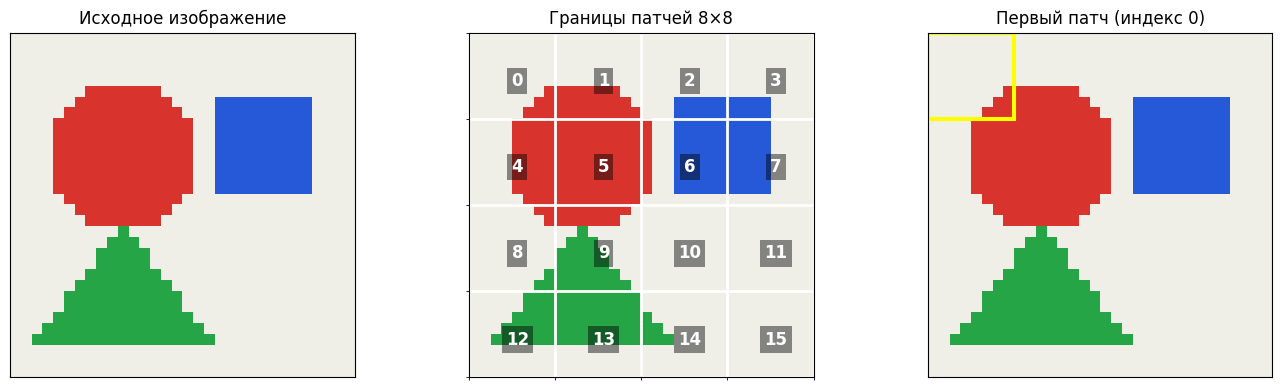

In [3]:
# Синтетическое RGB-изображение для иллюстрации patchification.
# Создаём плавный фон и несколько цветных областей без внешнего датасета.
H0 = W0 = 32
yy, xx = np.mgrid[0:H0, 0:W0]
image_demo = np.zeros((H0, W0, 3), dtype=np.float32)
image_demo[:] = [0.94, 0.94, 0.91]
image_demo[(xx - 10) ** 2 + (yy - 11) ** 2 < 7 ** 2] = [0.85, 0.20, 0.18]
image_demo[(xx > 18) & (xx < 28) & (yy > 5) & (yy < 15)] = [0.15, 0.35, 0.85]
tri = (yy > 17) & (yy < 29) & (np.abs(xx - 10) < (yy - 17) * 0.75)
image_demo[tri] = [0.15, 0.65, 0.28]

P = 8
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(image_demo)
axes[0].set_title("Исходное изображение")
axes[0].set_xticks(range(0, 33, 8)); axes[0].set_yticks(range(0, 33, 8))
axes[0].grid(color="white", linewidth=1.5)
axes[1].imshow(image_demo)
axes[1].set_title("Границы патчей 8×8")
for r in range(4):
    for c in range(4):
        axes[1].text(c * 8 + 4, r * 8 + 4, str(r * 4 + c), ha="center", va="center",
                     color="white", fontsize=12, weight="bold",
                     bbox=dict(facecolor="black", alpha=0.45, edgecolor="none", pad=3))
axes[1].set_xticks(np.arange(-.5, 32, 8), minor=True)
axes[1].set_yticks(np.arange(-.5, 32, 8), minor=True)
axes[1].grid(which="minor", color="white", linewidth=2)
axes[2].imshow(image_demo)
axes[2].set_title("Первый патч (индекс 0)")
axes[2].add_patch(plt.Rectangle((-.5, -.5), 8, 8, fill=False, edgecolor="yellow", linewidth=3))
for ax in axes:
    ax.set_xlim(-.5, 31.5); ax.set_ylim(31.5, -.5)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

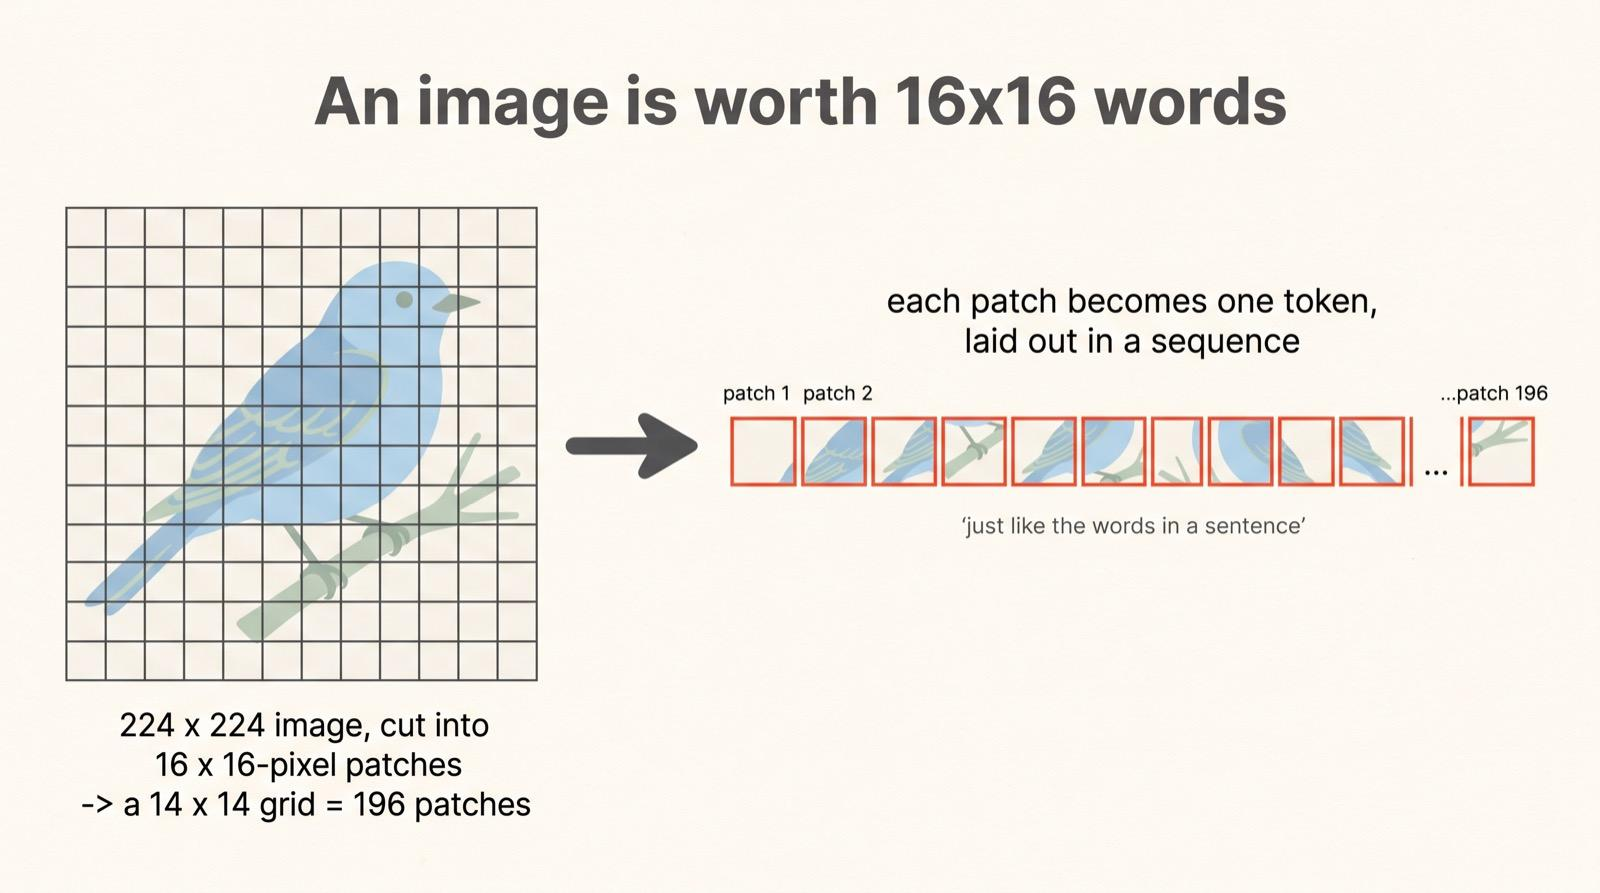


### 1.4. Реализуем patchification руками

Вход PyTorch имеет формат `(B, C, H, W)`. Для начала используем `unfold`: он выделяет окна, не меняя значения пикселей. Затем переставляем оси так, чтобы координаты патча шли перед координатами внутри патча, и разворачиваем последние измерения в вектор.

Обратите внимание: **patchification сама по себе не обучает ничего**. Это лишь детерминированная перестановка и группировка пикселей. Обучаемые параметры появляются на следующем шаге — в проекции патча в embedding.

In [52]:
def patchify(images: torch.Tensor, patch_size: int) -> torch.Tensor:
    """(B, C, H, W) -> (B, N, C * patch_size * patch_size).

    Патчи неперекрывающиеся; порядок — слева направо, сверху вниз.
    H и W должны делиться на patch_size.
    """
    if images.ndim != 4:
        raise ValueError("Ожидается тензор формы (B, C, H, W)")
    B, C, H, W = images.shape
    if H % patch_size or W % patch_size:
        raise ValueError("H и W должны делиться на patch_size")
    patches = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    # Сейчас: (B, C, grid_h, grid_w, P, P)
    patches = patches.permute(0, 2, 3, 1, 4, 5)
    # Теперь: (B, grid_h, grid_w, C, P, P) -> (B, N, C*P*P)
    return patches.reshape(B, (H // patch_size) * (W // patch_size), C * patch_size * patch_size)

image_tensor = torch.from_numpy(image_demo).permute(2, 0, 1).unsqueeze(0)
patch_vectors = patchify(image_tensor, patch_size=8)
print("Изображение:", tuple(image_tensor.shape))
print("Патчи:", tuple(patch_vectors.shape), "= (B=1, N=16, P²C=192)")
print("Первые 12 значений первого патча:", patch_vectors[0, 0, :12])

Изображение: (1, 3, 32, 32)
Патчи: (1, 16, 192) = (B=1, N=16, P²C=192)
Первые 12 значений первого патча: tensor([0.9400, 0.9400, 0.9400, 0.9400, 0.9400, 0.9400, 0.9400, 0.9400, 0.9400,
        0.9400, 0.9400, 0.9400])


### 1.5. Линейная проекция: от пикселей к признакам

Вектор патча из `P²C` пикселей — это ещё не embedding, который Transformer ожидает для каждого токена. Для каждого патча применяется одна и та же обучаемая линейная проекция:

$$
 e_i = x_{p,i} W + b, \qquad
W \in \mathbb{R}^{(P^2C)\times D}.
$$

Это аналог token embedding в языковой модели: вместо индекса слова на вход приходит вектор сырых пикселей, а линейный слой переводит его в пространство признаков фиксированной размерности `D`.

В реализациях ViT этот шаг часто записан как `Conv2d(kernel_size=P, stride=P)`. Это не «свёрточная сеть в обычном смысле»: при kernel и stride, равных размеру патча, каждый фильтр видит ровно один неперекрывающийся патч. Такая свёртка математически эквивалентна общей линейной проекции развёрнутого патча.

In [5]:
P = 8
D = 64
linear_projection = nn.Linear(3 * P * P, D)
patch_embeddings_linear = linear_projection(patchify(image_tensor, P))
conv_projection = nn.Conv2d(3, D, kernel_size=P, stride=P)
# Для проверки эквивалентности переносим веса Linear в Conv2d.
with torch.no_grad():
    conv_projection.weight.copy_(linear_projection.weight.reshape(D, 3, P, P))
    conv_projection.bias.copy_(linear_projection.bias)
patch_embeddings_conv = conv_projection(image_tensor).flatten(2).transpose(1, 2)
print("Linear:", tuple(patch_embeddings_linear.shape))
print("Conv2d:", tuple(patch_embeddings_conv.shape))
print("Максимальная разница:", (patch_embeddings_linear - patch_embeddings_conv).abs().max().item())

Linear: (1, 16, 64)
Conv2d: (1, 16, 64)
Максимальная разница: 8.344650268554688e-07


## 2. Vision Transformer (ViT)

Patchification даёт последовательность, но этого ещё недостаточно. Теперь можно почти без изменений применить знакомый Transformer encoder.

### 2.1. Полный путь от изображения к предсказанию

```text
Изображение (B, 3, H, W)
          │
          ▼
Разбиение на P×P патчи
          │
          ▼
Flatten каждого патча + Linear / Conv2d projection
          │
          ▼
Патчевые embeddings: (B, N, D)
          │
     добавить позиционные embeddings
          │
    добавить обучаемый [CLS] token
          │
          ▼
Transformer Encoder (обычный self-attention)
          │
          ▼
Вектор позиции [CLS]
          │
          ▼
Linear / MLP head → классы
```

### 2.2. Зачем нужны positional embeddings

У изображения есть геометрия: патч в левом верхнем углу и патч в правом нижнем — не одно и то же. Но self-attention сам по себе не знает, откуда пришёл каждый патч. Если переставить патчи, то без позиционной информации модель получит переставленную последовательность и не узнает, что поменялась их геометрическая раскладка.

Поэтому к embedding патча прибавляют **positional embedding** — обучаемый вектор, соответствующий индексу патча в сетке:

$$
z_i = e_i + p_i.
$$

В базовом ViT это обычно обучаемые абсолютные позиционные embeddings. Они сообщают Transformer, где находился каждый патч в исходном изображении.

### 2.3. Что такое `[CLS]` token

Добавляется ещё один обучаемый вектор — **class token**, обычно записываемый как `[CLS]`. Он не соответствует никакому участку изображения. Это дополнительная позиция, которая с самого начала присутствует в последовательности и через self-attention может собирать информацию со всех патчей.

После нескольких Transformer-блоков вектор на позиции `[CLS]` используется как обобщённое представление всего изображения. К нему применяют классификационную голову. Это похоже на то, как в семинаре 7–8 мы использовали специальный токен в последовательной модели, но здесь он агрегирует изображение.

```text
[CLS]   patch 0   patch 1   patch 2   ...   patch N-1
  │        │         │         │                │
  └────────┴─────────┴─────────┴────────────────┘
                    │
             Transformer Encoder
                    │
       [CLS]'   patch 0'  patch 1' ...
          │
     классификационная голова
          │
       logits классов
```

**Важное отличие от autoregressive Transformer:** ViT для классификации использует обычный двунаправленный self-attention. Патчу разрешено смотреть на все остальные патчи; causal mask здесь не нужна. Мы не предсказываем «следующий патч», а строим общее представление изображения.

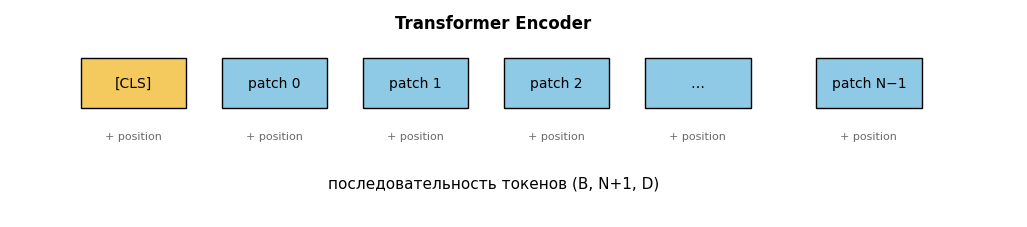

In [6]:
# Схематически покажем, как меняется последовательность.
fig, ax = plt.subplots(figsize=(13, 2.7))
ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis("off")
labels = ["[CLS]", "patch 0", "patch 1", "patch 2", "…", "patch N−1"]
xs = [0.7, 2.1, 3.5, 4.9, 6.3, 8.0]
for i, (x, label) in enumerate(zip(xs, labels)):
    color = "#f4c95d" if i == 0 else "#8ecae6"
    ax.add_patch(plt.Rectangle((x, 1.05), 1.05, 0.48, facecolor=color, edgecolor="black", linewidth=1))
    ax.text(x + 0.525, 1.29, label, ha="center", va="center", fontsize=10)
    ax.text(x + 0.525, 0.78, "+ position", ha="center", va="center", fontsize=8, color="dimgray")
ax.annotate("последовательность токенов (B, N+1, D)", xy=(4.8, 0.28), ha="center", fontsize=11)
ax.annotate("Transformer Encoder", xy=(4.8, 1.82), ha="center", fontsize=12, weight="bold")
plt.show()

### 2.4. Реализуем компактный ViT

Для наглядности сделаем небольшой encoder:

1. `Conv2d` с `kernel_size=stride=patch_size` превращает каждый патч в embedding.
2. Добавляем `[CLS]` и позиционные embeddings.
3. Пропускаем всю последовательность через несколько `TransformerEncoderLayer`.
4. Нормализуем выход `[CLS]` и, при необходимости, классифицируем его.

Используем `batch_first=True`, чтобы сохранять привычный формат `(B, T, D)`. `norm_first=True` задаёт Pre-LN-вариант блока, который уже обсуждали в предыдущем семинаре. Слои создаются отдельно: при использовании `nn.TransformerEncoder` с одним шаблонным слоем документация PyTorch предупреждает, что копии слоёв начинают с одинаково инициализированных параметров.

In [53]:
class TinyViT(nn.Module):
    def __init__(self, image_size=32, patch_size=4, in_channels=3,
                 d_model=64, n_heads=4, n_layers=2, num_classes=None):
        super().__init__()
        if image_size % patch_size != 0:
            raise ValueError("image_size должен делиться на patch_size")
        self.patch_size = patch_size
        self.patch_embed = nn.Conv2d(in_channels, d_model, kernel_size=patch_size, stride=patch_size)
        n_patches = (image_size // patch_size) ** 2
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, d_model))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.blocks = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model, nhead=n_heads, dim_feedforward=4 * d_model,
                dropout=0.0, activation="gelu", batch_first=True, norm_first=True
            )
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes) if num_classes is not None else None

    def forward_features(self, images):
        x = self.patch_embed(images)                 # (B, D, H/P, W/P)
        x = x.flatten(2).transpose(1, 2)            # (B, N, D)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat([cls, x], dim=1) + self.pos_embed
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        return x[:, 0]                               # (B, D): представление [CLS]

    def forward(self, images):
        features = self.forward_features(images)
        return features if self.head is None else self.head(features)

vit_demo = TinyViT(image_size=32, patch_size=8, d_model=64, n_heads=4, n_layers=2, num_classes=3).to(device)
with torch.no_grad():
    sample_features = vit_demo.forward_features(image_tensor.to(device))
    sample_logits = vit_demo(image_tensor.to(device))
print("Изображение:", tuple(image_tensor.shape))
print("Число patch-токенов:", (32 // 8) ** 2)
print("[CLS] representation:", tuple(sample_features.shape))
print("Классификационные logits:", tuple(sample_logits.shape))

Изображение: (1, 3, 32, 32)
Число patch-токенов: 16
[CLS] representation: (1, 64)
Классификационные logits: (1, 3)


### 2.5. Размер патча — компромисс между деталями и стоимостью

При фиксированном размере изображения уменьшение `patch_size` увеличивает число токенов квадратично. Например, для изображения `224 × 224`:

- `P=16` даёт `14 × 14 = 196` патчей;
- `P=8` даёт `28 × 28 = 784` патча — в 4 раза больше токенов и примерно в 16 раз больше элементов в матрице attention;
- `P=32` даёт `7 × 7 = 49` патчей.

Это не означает, что маленькие патчи всегда лучше. Деталей становится больше, но растут память и вычисления. Размер патча выбирают под задачу, разрешение и бюджет модели.

In [54]:
image_size = 224
for p in [4, 8, 16, 32]:
    n = (image_size // p) ** 2
    print(f"patch={p:2d}: {n:4d} токенов; attention matrix: {n*n:>8,} элементов на одну голову")

patch= 4: 3136 токенов; attention matrix: 9,834,496 элементов на одну голову
patch= 8:  784 токенов; attention matrix:  614,656 элементов на одну голову
patch=16:  196 токенов; attention matrix:   38,416 элементов на одну голову
patch=32:   49 токенов; attention matrix:    2,401 элементов на одну голову


## 3. CLIP: связываем изображения и текст

### 3.1. Какая проблема решается

Обычная классификационная модель учится выбирать классы из заранее заданного списка: например, `cat`, `dog`, `car`. Чтобы добавить новый класс, часто требуется подготовить примеры и дообучить классификатор.

CLIP (*Contrastive Language–Image Pre-training*) использует другой тип обучения: модель получает пары **(изображение, текстовое описание)** и учится делать embedding изображения похожим на embedding соответствующего текста. Например:

- изображение: фотография красного велосипеда;
- положительный текст: «красный велосипед на улице»;
- отрицательные тексты: «собака на траве», «синяя чашка на столе».

Это **контрастивное обучение**: правильная пара должна иметь высокое сходство, а неправильные пары из того же батча — низкое.

### 3.2. Два энкодера и общее пространство

CLIP состоит из двух ветвей:

- **image encoder** превращает изображение в вектор;
- **text encoder** превращает описание в вектор.

Затем отдельные projection heads переводят эти векторы в пространство общей размерности. Векторы нормализуются по L2-норме:

$$
\hat v_i = \frac{v_i}{\|v_i\|_2}, \qquad
\hat t_i = \frac{t_i}{\|t_i\|_2}.
$$

После нормализации скалярное произведение равно cosine similarity. Поэтому embedding можно сравнивать одним и тем же правилом независимо от того, пришёл он из изображения или из текста.

```text
Изображение ─► image encoder ─► projection ─► L2 normalize ─► v̂
                                                              │
                                                              ├─► cosine similarity
                                                              │
Текст ───────► text encoder  ─► projection ─► L2 normalize ─► t̂
```

В оригинальном CLIP image encoder — ResNet или ViT, а text encoder — Transformer. В нашей маленькой демонстрации image encoder будет ViT, а text encoder — намеренно упрощённая модель `Embedding + mean pooling`. Это позволяет сосредоточиться на контрастивной функции потерь; такой текстовый encoder **не является точной реализацией CLIP**.

### 3.3. Similarity matrix и правильные пары

Пусть в батче есть `N` изображений и соответствующие им `N` текстов. Строим матрицу сходств:

$$
S_{ij} = \frac{\hat v_i^\top \hat t_j}{\tau},
\qquad S\in\mathbb{R}^{N\times N}.
$$

`S[i, j]` показывает, насколько изображение `i` похоже на текст `j`. В обучающем батче положительные пары стоят на диагонали: изображение с индексом `i` соответствует тексту с индексом `i`. Все остальные элементы — отрицательные примеры данного батча.

Параметр `τ` — **temperature**. При маленькой temperature различия между похожими и непохожими парами усиливаются после softmax; при большой — распределение становится более мягким. В CLIP масштаб сходства часто задают обучаемым множителем `exp(logit_scale)`, то есть обратной temperature.

In [13]:
# Три изображения и три текста.
# Предполагается, что пары с одинаковыми индексами соответствуют друг другу.

sim_demo = torch.tensor([
    [0.90, 0.20, 0.10],
    [0.15, 0.82, 0.30],
    [0.05, 0.25, 0.88],
], dtype=torch.float32)

tau_demo = 0.2
logits_demo = sim_demo / tau_demo
labels_demo = torch.arange(3)

# 1. Для каждого изображения ищем подходящий текст.
probs_i2t = torch.softmax(logits_demo, dim=1)

# 2. Для каждого текста ищем подходящее изображение.
probs_t2i = torch.softmax(logits_demo, dim=0)

# 3. Вычисляем ошибки в обоих направлениях.
loss_i2t = F.cross_entropy(logits_demo, labels_demo)
loss_t2i = F.cross_entropy(logits_demo.T, labels_demo)

# 4. Объединяем ошибки.
loss_clip = (loss_i2t + loss_t2i) / 2

print("Вероятности выбора текста для каждого изображения:")
print(probs_i2t)

print("\nВероятности выбора изображения для каждого текста:")
print(probs_t2i)

print(f"\nImage → Text loss: {loss_i2t.item():.4f}")
print(f"Text → Image loss: {loss_t2i.item():.4f}")
print(f"CLIP loss: {loss_clip.item():.4f}")

Вероятности выбора текста для каждого изображения:
tensor([[0.9537, 0.0288, 0.0175],
        [0.0316, 0.9014, 0.0670],
        [0.0149, 0.0405, 0.9446]])

Вероятности выбора изображения для каждого текста:
tensor([[0.9636, 0.0408, 0.0188],
        [0.0227, 0.9067, 0.0512],
        [0.0137, 0.0524, 0.9300]])

Image → Text loss: 0.0694
Text → Image loss: 0.0692
CLIP loss: 0.0693


### 3.4. Что такое InfoNCE loss

Для каждого изображения правильным ответом является индекс его текста. Поэтому можно применить обычную cross-entropy к каждой строке similarity matrix. Аналогично, для каждого текста правильный ответ — индекс соответствующего изображения, и cross-entropy считается по транспонированной матрице.

$$
\mathcal L_{i\to t} = -\frac{1}{N}\sum_i
\log\frac{\exp(S_{ii})}{\sum_j\exp(S_{ij})},
$$

$$
\mathcal L_{t\to i} = -\frac{1}{N}\sum_i
\log\frac{\exp(S_{ii})}{\sum_j\exp(S_{ji})},
\qquad
\mathcal L = \frac{\mathcal L_{i\to t}+\mathcal L_{t\to i}}{2}.
$$

Это симметричная contrastive objective, используемая в CLIP. Её часто относят к семейству **InfoNCE**: у правильной пары вероятность должна быть высокой относительно остальных пар в батче.

Важные детали:

1. **Положительный пример** — соответствующие друг другу изображение и текст.
2. **Отрицательные примеры** — остальные тексты для данного изображения (и наоборот).
3. **Диагональ** similarity matrix — правильные пары, если порядок изображений и текстов совпадает.
4. Увеличение размера батча даёт больше отрицательных примеров, но повышает вычислительную стоимость.
5. Если в батче есть несколько разных описаний одного и того же изображения/смысла, простая диагональная cross-entropy может ошибочно считать их отрицательными. В реальных системах это важная проблема false negatives.

**Связь с тем, что уже знаем:** здесь снова используется softmax + cross-entropy, как в предыдущих семинарах. Изменилось не устройство softmax, а то, что мы классифицируем не фиксированные классы изображения, а правильный текст среди текстов батча.

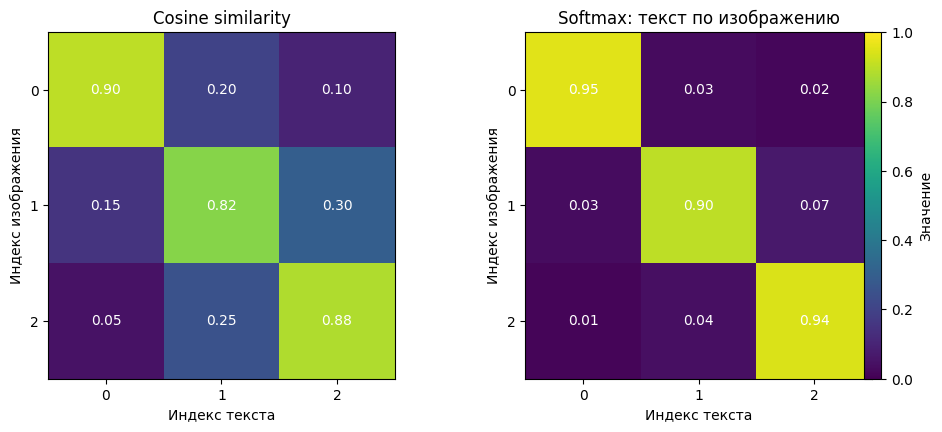

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

matrices = [
    (sim_demo.numpy(), "Cosine similarity"),
    (probs_i2t.numpy(), "Softmax: текст по изображению"),
]

for ax, (matrix, title) in zip(axes, matrices):
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")

    ax.set_title(title)
    ax.set_xlabel("Индекс текста")
    ax.set_ylabel("Индекс изображения")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))

    for i in range(3):
        for j in range(3):
            ax.text(
                j, i, f"{matrix[i, j]:.2f}",
                ha="center", va="center",
                color="white"
            )

# Общая цветовая шкала справа от обеих матриц.
fig.colorbar(
    im,
    ax=axes,
    label="Значение",
    fraction=0.035,
    pad=0.04
)

fig.subplots_adjust(wspace=0.35, right=0.88)
plt.show()

## 4. Мини-CLIP: обучим image–text embeddings на синтетических парах

Теперь объединим разобранные компоненты. Чтобы примеры были проверяемыми и не зависели от внешней загрузки, создадим 18 изображений: три формы, три цвета и два положения. Каждому изображению соответствует уникальное короткое описание, например `a red circle on the left`.

Эта задача намеренно простая: модель должна научиться связывать визуальные признаки с названиями формы, цвета и положения. Это демонстрация **механики** CLIP, а не полноценное pretraining на естественных изображениях и текстах.

Для мини-корпуса используем bag-of-words text encoder: токены слов переводятся в embeddings, затем усредняются с исключением padding. В настоящем CLIP текстовая последовательность обрабатывается Transformer-энкодером.

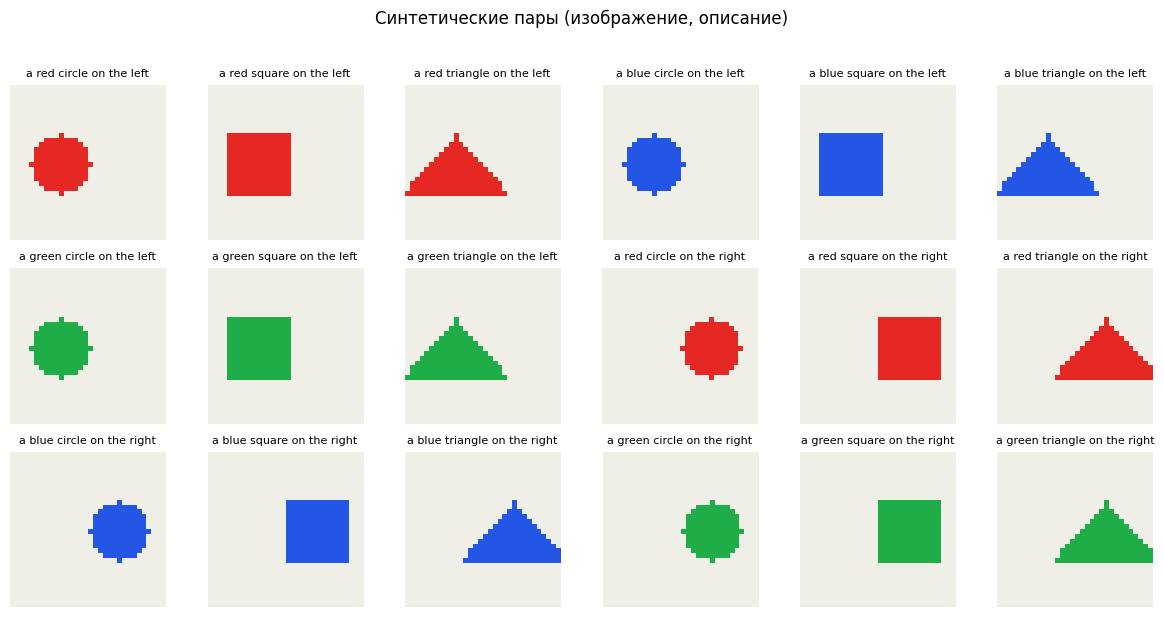

Число пар: 18


In [16]:
# Генерация небольшого набора изображений 32×32.
COLORS = {
    "red": np.array([0.90, 0.16, 0.14], dtype=np.float32),
    "blue": np.array([0.14, 0.34, 0.90], dtype=np.float32),
    "green": np.array([0.12, 0.68, 0.28], dtype=np.float32),
}
SHAPES = ["circle", "square", "triangle"]
POSITIONS = ["left", "right"]

def make_shape_image(color_name, shape_name, position, size=32):
    yy, xx = np.mgrid[0:size, 0:size]
    img = np.zeros((size, size, 3), dtype=np.float32)
    img[:] = [0.94, 0.94, 0.91]
    cx = 10 if position == "left" else 22
    cy = 16
    r = 6
    if shape_name == "circle":
        mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
    elif shape_name == "square":
        mask = (np.abs(xx - cx) <= r) & (np.abs(yy - cy) <= r)
    elif shape_name == "triangle":
        mask = (yy >= cy - r) & (yy <= cy + r) & (np.abs(xx - cx) <= (yy - (cy - r)) * 0.9)
    else:
        raise ValueError(shape_name)
    img[mask] = COLORS[color_name]
    return img

captions = []
images_np = []
metadata = []
for position in POSITIONS:
    for color in COLORS:
        for shape in SHAPES:
            images_np.append(make_shape_image(color, shape, position))
            captions.append(f"a {color} {shape} on the {position}")
            metadata.append((color, shape, position))
images_np = np.stack(images_np)
images_clip = torch.from_numpy(images_np).permute(0, 3, 1, 2).contiguous()

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_np[i])
    ax.set_title(captions[i], fontsize=8)
    ax.axis("off")
plt.suptitle("Синтетические пары (изображение, описание)", y=1.02)
plt.tight_layout(); plt.show()
print("Число пар:", len(captions))

### 4.1. Токенизация коротких описаний

Здесь достаточно простого словаря: каждое слово получает целочисленный ID. Все предложения дополняем `PAD` до общей длины. `PAD` не должен влиять на mean pooling — поэтому при усреднении используем маску `token_id != PAD_ID`.

Это не универсальный tokenizer: он подходит только для нашего искусственного набора коротких предложений. В реальном CLIP используются специализированные правила токенизации и обучаемый Transformer text encoder.

In [17]:
PAD = "<pad>"
words = sorted({word for caption in captions for word in caption.split()})
vocab = {PAD: 0, **{word: i + 1 for i, word in enumerate(words)}}
MAX_TEXT_LEN = max(len(c.split()) for c in captions)

def encode_captions(texts):
    encoded = torch.zeros(len(texts), MAX_TEXT_LEN, dtype=torch.long)
    for i, text in enumerate(texts):
        ids = [vocab[word] for word in text.split()]
        encoded[i, :len(ids)] = torch.tensor(ids)
    return encoded

tokens_clip = encode_captions(captions)
print("Словарь:", vocab)
print("Токены:", tuple(tokens_clip.shape))
print("Первое описание:", captions[0])
print("Его ID:", tokens_clip[0].tolist())

Словарь: {'<pad>': 0, 'a': 1, 'blue': 2, 'circle': 3, 'green': 4, 'left': 5, 'on': 6, 'red': 7, 'right': 8, 'square': 9, 'the': 10, 'triangle': 11}
Токены: (18, 6)
Первое описание: a red circle on the left
Его ID: [1, 7, 3, 6, 10, 5]


### 4.2. Энкодеры и contrastive objective

В image branch применим наш `TinyViT`. Из `[CLS]` получим один вектор изображения. В text branch усредним embedding слов. Затем обе ветви получат линейную проекцию в одинаковую размерность `projection_dim` и L2-нормализацию.

После этого задача CLIP сводится к similarity matrix и двум cross-entropy loss — как в предыдущем численном примере.

In [56]:
class MeanTextEncoder(nn.Module):
    """Учебное упрощение: Embedding слов + mean pooling без Transformer."""
    def __init__(self, vocab_size, d_text=48):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_text, padding_idx=0)
        self.norm = nn.LayerNorm(d_text)

    def forward(self, token_ids):
        mask = token_ids.ne(0).unsqueeze(-1)       # (B, L, 1)
        emb = self.embedding(token_ids)            # (B, L, d_text)
        pooled = (emb * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        return self.norm(pooled)

class MiniCLIP(nn.Module):
    def __init__(self, vocab_size, projection_dim=32):
        super().__init__()
        self.image_encoder = TinyViT(
            image_size=32, patch_size=4, d_model=64, n_heads=4, n_layers=2, num_classes=None
        )
        self.text_encoder = MeanTextEncoder(vocab_size, d_text=48)
        self.image_projection = nn.Linear(64, projection_dim, bias=False)
        self.text_projection = nn.Linear(48, projection_dim, bias=False)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def encode_image(self, images):
        x = self.image_projection(self.image_encoder(images))
        return F.normalize(x, dim=-1)

    def encode_text(self, token_ids):
        x = self.text_projection(self.text_encoder(token_ids))
        return F.normalize(x, dim=-1)

    def forward(self, images, token_ids):
        image_features = self.encode_image(images)
        text_features = self.encode_text(token_ids)
        scale = self.logit_scale.exp().clamp(max=100.0)
        logits_per_image = scale * image_features @ text_features.T
        logits_per_text = logits_per_image.T
        return logits_per_image, logits_per_text

def clip_loss(logits_per_image, logits_per_text):
    targets = torch.arange(logits_per_image.shape[0], device=logits_per_image.device)
    loss_i = F.cross_entropy(logits_per_image, targets)
    loss_t = F.cross_entropy(logits_per_text, targets)
    return (loss_i + loss_t) / 2, loss_i.detach(), loss_t.detach()

clip_model = MiniCLIP(vocab_size=len(vocab), projection_dim=32).to(device)
images_clip_device = images_clip.to(device)
tokens_clip_device = tokens_clip.to(device)
with torch.no_grad():
    initial_logits_i, initial_logits_t = clip_model(images_clip_device, tokens_clip_device)
print("Similarity logits:", tuple(initial_logits_i.shape), "(N images, N texts)")
print("Диагональ — правильные пары; остальные ячейки — отрицательные пары в батче")

Similarity logits: (18, 18) (N images, N texts)
Диагональ — правильные пары; остальные ячейки — отрицательные пары в батче


Обучим модель на всех 18 парах. В каждом шаге диагональ similarity matrix является целевым соответствием. Для такого маленького синтетического набора полный батч удобен: каждая пара видит остальные 17 текстов/изображений как отрицательные примеры.

В больших CLIP-подобных системах батчи намного крупнее, данные разнообразнее, а обработка изображений и текстов значительно сложнее. Здесь цель — увидеть, как уменьшается контрастивный loss и как после обучения можно искать соответствия.

Время обучения: 2.0 с на cpu
Loss: 3.807 → 0.004


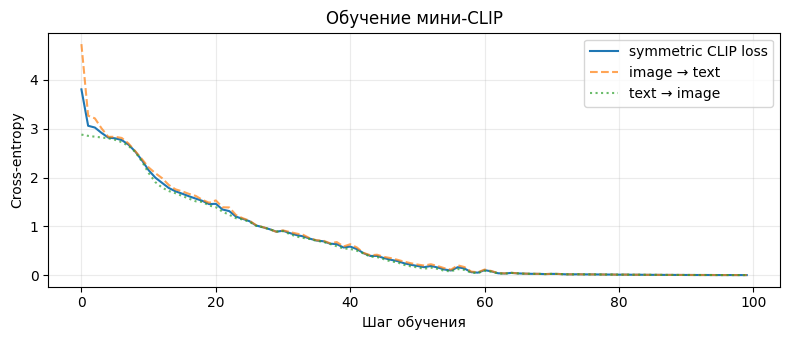

In [57]:
optimizer_clip = torch.optim.AdamW(clip_model.parameters(), lr=1e-3, weight_decay=1e-4)
clip_history = []
clip_steps = 100
start_time = time.time()
for step in range(clip_steps):
    clip_model.train()
    optimizer_clip.zero_grad(set_to_none=True)
    logits_i, logits_t = clip_model(images_clip_device, tokens_clip_device)
    loss, loss_i, loss_t = clip_loss(logits_i, logits_t)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(clip_model.parameters(), max_norm=1.0)
    optimizer_clip.step()
    clip_history.append((loss.item(), loss_i.item(), loss_t.item()))
print(f"Время обучения: {time.time() - start_time:.1f} с на {device}")
print(f"Loss: {clip_history[0][0]:.3f} → {clip_history[-1][0]:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([x[0] for x in clip_history], label="symmetric CLIP loss")
ax.plot([x[1] for x in clip_history], linestyle="--", alpha=0.7, label="image → text")
ax.plot([x[2] for x in clip_history], linestyle=":", alpha=0.7, label="text → image")
ax.set_xlabel("Шаг обучения"); ax.set_ylabel("Cross-entropy")
ax.set_title("Обучение мини-CLIP"); ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### 4.3. Image–text retrieval

После обучения мы можем решать две симметричные задачи:

- **image → text:** для данного изображения найти наиболее похожее описание;
- **text → image:** для данного описания найти наиболее похожее изображение.

Никакого дополнительного классификатора для этого не требуется. Мы вычисляем embedding запросного объекта, считаем cosine similarity со всеми кандидатами и сортируем по сходству.

В реальном retrieval-сервисе галерея может быть очень большой. Обычно embeddings заранее вычисляют и индексируют, а для каждого нового запроса ищут ближайших соседей. В этой демонстрации галерея содержит всего 18 объектов, поэтому достаточно матричного умножения.

Top-1 exact-pair retrieval accuracy: 100.0%
Запрос-изображение: a blue triangle on the left
Топ-5 найденных описаний:
1. a blue triangle on the left    similarity=0.977
2. a red triangle on the left     similarity=0.520
3. a green triangle on the left   similarity=0.511
4. a blue triangle on the right   similarity=0.505
5. a blue square on the left      similarity=0.395


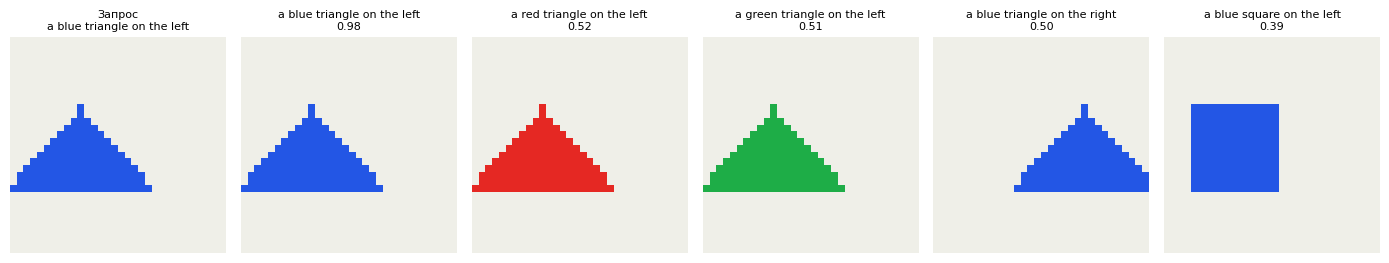

In [58]:
clip_model.eval()
with torch.inference_mode():
    image_emb = clip_model.encode_image(images_clip_device)
    text_emb = clip_model.encode_text(tokens_clip_device)
    retrieval_similarity = image_emb @ text_emb.T
retrieval_top1 = retrieval_similarity.argmax(dim=1)
retrieval_accuracy = (retrieval_top1 == torch.arange(len(captions), device=device)).float().mean().item()
print(f"Top-1 exact-pair retrieval accuracy: {retrieval_accuracy:.1%}")

query_image_id = 5
scores = retrieval_similarity[query_image_id]
topk = torch.topk(scores, k=5).indices.cpu().tolist()
print("Запрос-изображение:", captions[query_image_id])
print("Топ-5 найденных описаний:")
for rank, j in enumerate(topk, start=1):
    print(f"{rank}. {captions[j]:30s} similarity={scores[j].item():.3f}")

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(images_np[query_image_id]); axes[0].set_title("Запрос\n" + captions[query_image_id], fontsize=8); axes[0].axis("off")
for ax, j in zip(axes[1:], topk[:5]):
    ax.imshow(images_np[j]); ax.set_title(captions[j] + f"\n{scores[j].item():.2f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

**Как интерпретировать результат:** если модель выучила соответствия, диагональ similarity matrix должна быть среди самых больших значений, а правильное описание должно попадать в начало списка. При этом высокий score не означает вероятность в калиброванном смысле: это совместимость embeddings, масштабированная обучаемым коэффициентом.



Текстовый запрос: triangle green left
Наиболее подходящие изображения:
1. a green triangle on the left   similarity=0.913
2. a blue triangle on the left    similarity=0.612
3. a red triangle on the left     similarity=0.566
4. a green circle on the left     similarity=0.501
5. a green square on the left     similarity=0.396


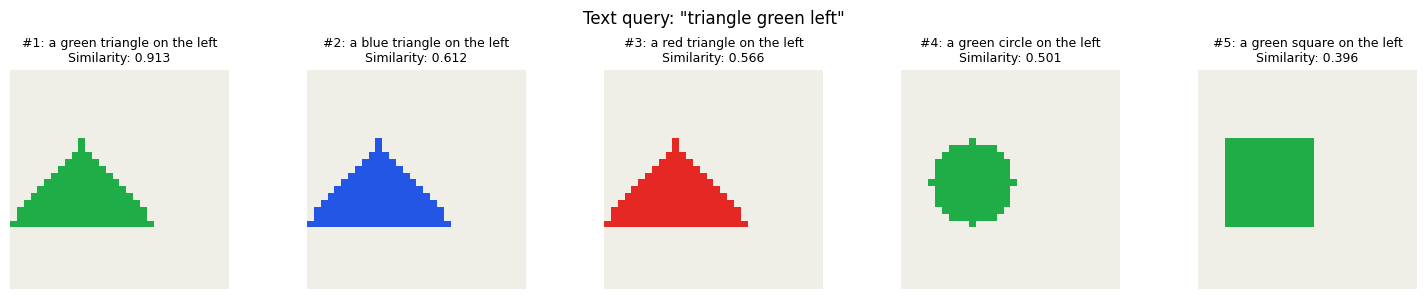

In [59]:
# Вводим текстовый запрос.
query_text = input("Введите описание изображения: ").strip().lower()

if not query_text:
    raise ValueError("Пустой текстовый запрос.")

# Проверяем, что все слова присутствуют в словаре модели.
query_words = query_text.split()
unknown_words = sorted(set(query_words) - set(vocab))

if unknown_words:
    raise ValueError(
        f"Неизвестные слова: {unknown_words}\n"
        f"Доступные слова: {sorted(w for w in vocab if w != PAD)}"
    )

# Кодируем текст в последовательность токенов.
# Padding не требуется: MeanTextEncoder усредняет только непустые токены.
query_tokens = torch.tensor(
    [[vocab[word] for word in query_words]],
    dtype=torch.long,
    device=device
)

clip_model.eval()

with torch.inference_mode():
    # Получаем эмбеддинги всех изображений.
    image_emb = clip_model.encode_image(images_clip_device)

    # Получаем эмбеддинг текстового запроса.
    query_emb = clip_model.encode_text(query_tokens)

    # Считаем cosine similarity запроса со всеми изображениями.
    # Размерность: [1, D] @ [D, N] -> [1, N].
    scores = (query_emb @ image_emb.T).squeeze(0)

# Выбираем пять наиболее подходящих изображений.
k = min(5, len(images_np))
topk = torch.topk(scores, k=k).indices.cpu().tolist()

print(f"\nТекстовый запрос: {query_text}")
print("Наиболее подходящие изображения:")

for rank, idx in enumerate(topk, start=1):
    print(f"{rank}. {captions[idx]:30s} similarity={scores[idx].item():.3f}")

# Визуализируем результаты.
fig, axes = plt.subplots(1, k, figsize=(3 * k, 3))

if k == 1:
    axes = [axes]

for rank, (ax, idx) in enumerate(zip(axes, topk), start=1):
    ax.imshow(images_np[idx])
    ax.set_title(
        f"#{rank}: {captions[idx]}\nSimilarity: {scores[idx].item():.3f}",
        fontsize=9
    )
    ax.axis("off")

fig.suptitle(f'Text query: "{query_text}"', fontsize=12)
fig.tight_layout()
plt.show()

## 5. DETR: детекция как предсказание множества

### 5.1. Что было в детекторах раньше

В семинарах 5–6 мы разбирали типичный pipeline детекции: сеть предсказывает много кандидатов, кандидаты привязаны к anchors или позициям feature map, затем применяется NMS, чтобы убрать дублирующие боксы.

**DETR (DEtection TRansformer)** предлагает другой взгляд: модель сразу предсказывает фиксированное множество слотов, каждый из которых может описывать один объект или сказать «объекта нет». Это задача **set prediction**.

Множество не имеет естественного порядка. Если на изображении есть кошка и велосипед, список `[кошка, велосипед]` описывает тот же набор объектов, что и `[велосипед, кошка]`. Поэтому нельзя просто сравнить первый predicted box с первым ground-truth box, второй со вторым и так далее: порядок произволен.

### 5.2. Архитектура DETR

Упрощённый поток данных выглядит так:

```text
Изображение
    │
    ▼
CNN backbone → feature map
    │
    ▼
Flatten feature map + positional encoding
    │
    ▼
Transformer Encoder  ◄── глобальные отношения между областями изображения
    │
    ▼
Transformer Decoder  ◄── Q обучаемых object queries
    │
    ▼
Q выходных векторов (слотов)
    │
    ├── Linear → class logits (включая no-object)
    └── MLP    → box (cx, cy, width, height)
```

**Object query** — обучаемый вектор, который играет роль слота для одного возможного объекта. Decoder обновляет эти слоты, используя cross-attention к памяти encoder. Query не является заранее заданным anchor, не фиксирует класс и не обозначает конкретную координату. В ходе обучения разные слоты специализируются на поиске разных объектов.

Если задали `Q=100` queries, модель выдаст 100 предсказаний независимо от того, сколько объектов на изображении. Для неиспользованных слотов правильный класс — специальный `no-object`. В оригинальном DETR число queries выбирается больше типичного числа объектов в изображении.



### 5.3. Как DETR сопоставляет предсказания с объектами?

Представим, что на изображении находятся три объекта: кошка, собака и мяч. В обучающих данных нам известны их классы и координаты.

DETR выдаёт пять предсказаний. Какие из них соответствуют кошке, собаке и мячу?

Проблема в том, что модель не знает заранее, какой именно выход отвечает за какой объект. Например, первое предсказание может оказаться кошкой, а четвёртое — собакой.

Для этого используется алгоритм Hungarian matching:

1. Сравниваем каждое предсказание с каждым настоящим объектом.
2. Оцениваем, насколько хорошо они совпадают: учитываем класс объекта и положение ограничивающей рамки.
3. Выбираем три разных предсказания, которые в сумме лучше всего соответствуют трём настоящим объектам.

Например:

| Предсказание | С каким объектом сопоставлено |
| ------------ | ----------------------------- |
| № 1          | Кошка                         |
| № 2          | Нет соответствия              |
| № 3          | Мяч                           |
| № 4          | Собака                        |
| № 5          | Нет соответствия              |

Алгоритм ищет наилучшее общее сопоставление, а не просто выбирает лучшее предсказание отдельно для каждого объекта. Это важно, потому что одному предсказанию нельзя назначить сразу два объекта.

После сопоставления модель обучается:

- предсказывать правильный класс объекта;
- точнее определять координаты его рамки;
- относить оставшиеся предсказания к специальному классу `no-object` (нет объекта).

Таким образом, Hungarian matching помогает DETR понять, какое предсказание за какой настоящий объект должно отвечать.

Важно: само сопоставление — это алгоритмический шаг, а не отдельная обучаемая нейросеть. После него вычисляется ошибка, по которой обновляются параметры модели.

#### Теперь формально


Это **двудольное сопоставление** (*bipartite matching*): слева — предсказания, справа — объекты разметки. Каждая пара имеет стоимость. Алгоритм Hungarian (в SciPy — `linear_sum_assignment`) находит глобально оптимальное назначение один-к-одному.

$$
\pi^* = \arg\min_{\pi\;\text{one-to-one}}
\sum_{j=1}^{M} C_{\pi(j),j}.
$$

Стоимость пары «предсказание `i` ↔ объект `j`» в DETR сочетает три компонента:

$$
C_{ij} = -p_i(c_j)
+ \lambda_{L1}\,\|b_i-b_j\|_1
+ \lambda_{GIoU}\,(1-\operatorname{GIoU}(b_i,b_j)).
$$

- `-p_i(c_j)` поощряет предсказание правильного класса;
- L1 distance сравнивает координаты боксов;
- `1 - GIoU` учитывает геометрическое совпадение, в том числе когда боксы не пересекаются.

Для поиска назначения стоимость считается без градиента — это дискретный алгоритмический шаг. После того как соответствия найдены, обычные дифференцируемые loss-функции обучают классы и координаты.

Матрица стоимостей (queries × GT):
 [[0.15 0.8  0.55]
 [0.2  0.25 0.7 ]
 [0.14 0.18 0.3 ]
 [0.45 0.42 0.12]
 [0.35 0.5  0.4 ]]
Выбранные пары (query, GT): [(0, 0), (2, 1), (3, 2)]
Суммарная стоимость: 0.44999999999999996


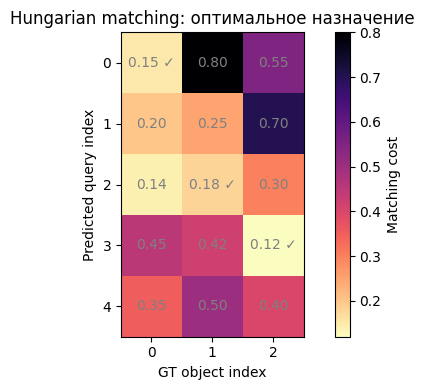

In [62]:
# Toy cost matrix: строки — 5 predicted queries, столбцы — 3 GT objects.
# Числа условные; алгоритм выбирает не самый дешёвый элемент в каждой колонке
# независимо, а глобальное назначение без повторного использования query.
cost_example = np.array([
    [0.15, 0.80, 0.55],
    [0.20, 0.25, 0.70],
    [0.14, 0.18, 0.30],
    [0.45, 0.42, 0.12],
    [0.35, 0.50, 0.40],
])
rows, cols = linear_sum_assignment(cost_example)
print("Матрица стоимостей (queries × GT):\n", cost_example)
print("Выбранные пары (query, GT):", list(zip(rows.tolist(), cols.tolist())))
print("Суммарная стоимость:", cost_example[rows, cols].sum())

fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(cost_example, cmap="magma_r")
ax.set_xlabel("GT object index"); ax.set_ylabel("Predicted query index")
ax.set_xticks(range(3)); ax.set_yticks(range(5))
for i in range(cost_example.shape[0]):
    for j in range(cost_example.shape[1]):
        mark = " ✓" if (i, j) in set(zip(rows.tolist(), cols.tolist())) else ""
        ax.text(j, i, f"{cost_example[i,j]:.2f}{mark}", ha="center", va="center", color="grey")
ax.set_title("Hungarian matching: оптимальное назначение")
fig.colorbar(im, ax=ax, label="Matching cost")
plt.tight_layout(); plt.show()

### 5.4. После matching: какие loss обучают модель

После назначения:

1. Каждый matched query должен предсказать класс соответствующего GT-объекта.
2. Каждый unmatched query должен предсказать класс `no-object`.
3. Для matched queries считаются регрессионные потери боксов: L1 и GIoU.
4. Для unmatched queries box loss не считается — у них нет соответствующего объекта.

Это важное разделение: Hungarian matching определяет, **какое предсказание сравнивать с каким объектом**, а cross-entropy / L1 / GIoU задают, **как исправлять предсказания градиентом**.

Поскольку пустых queries обычно много, `no-object` может доминировать в классификационной части. В оригинальном DETR для этого используется пониженный вес класса `no-object`.

### 5.5. Минимальная реализация forward DETR

Ниже — компактная архитектура, повторяющая основные идеи DETR: CNN feature map, позиционная информация, encoder, обучаемые object queries, decoder и две головы. Для простоты размер feature map фиксирован `8 × 8`, а backbone значительно меньше настоящего ResNet.

In [63]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=3):
        super().__init__()
        dims = [input_dim] + [hidden_dim] * (num_layers - 1) + [output_dim]
        self.layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = F.relu(layer(x))
        return self.layers[-1](x)

class TinyDETR(nn.Module):
    def __init__(self, num_classes=2, num_queries=5, d_model=64, n_heads=4, n_encoder=2, n_decoder=2):
        super().__init__()
        self.num_classes = num_classes
        self.num_queries = num_queries
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, d_model, kernel_size=3, stride=4, padding=1), nn.ReLU(),
        )
        self.pos_embed = nn.Parameter(torch.randn(1, d_model, 8, 8) * 0.02)
        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(d_model, n_heads, 4*d_model, dropout=0.0,
                                       activation="gelu", batch_first=True, norm_first=True)
            for _ in range(n_encoder)
        ])
        self.query_embed = nn.Embedding(num_queries, d_model)
        self.decoder_layers = nn.ModuleList([
            nn.TransformerDecoderLayer(d_model, n_heads, 4*d_model, dropout=0.0,
                                       activation="gelu", batch_first=True, norm_first=True)
            for _ in range(n_decoder)
        ])
        self.class_head = nn.Linear(d_model, num_classes + 1)  # + no-object
        self.box_head = MLP(d_model, d_model, 4, num_layers=3)

    def forward(self, images):
        features = self.backbone(images) + self.pos_embed
        memory = features.flatten(2).transpose(1, 2)            # (B, 64, D)
        for layer in self.encoder_layers:
            memory = layer(memory)
        queries = self.query_embed.weight.unsqueeze(0).expand(images.shape[0], -1, -1)
        decoded = queries
        for layer in self.decoder_layers:
            decoded = layer(decoded, memory)                    # cross-attention к memory
        logits = self.class_head(decoded)                       # (B, Q, C+1)
        boxes = self.box_head(decoded).sigmoid()                # (B, Q, 4), cxcywh в [0,1]
        return {"pred_logits": logits, "pred_boxes": boxes, "memory": memory}

detr_demo = TinyDETR(num_classes=2, num_queries=5).to(device)
with torch.no_grad():
    detr_out = detr_demo(torch.randn(2, 3, 64, 64, device=device))
print("Backbone/encoder memory:", tuple(detr_out["memory"].shape), "= (B=2, Hf*Wf=64, D=64)")
print("Class logits:", tuple(detr_out["pred_logits"].shape), "= (B, Q=5, 3 включая no-object)")
print("Box predictions:", tuple(detr_out["pred_boxes"].shape), "= (B, Q=5, cx, cy, w, h)")

Backbone/encoder memory: (2, 64, 64) = (B=2, Hf*Wf=64, D=64)
Class logits: (2, 5, 3) = (B, Q=5, 3 включая no-object)
Box predictions: (2, 5, 4) = (B, Q=5, cx, cy, w, h)


### 5.6. Реализуем matching cost и set loss

Для корректной геометрической части переведём боксы из `cxcywh` в `xyxy`, вычислим попарный IoU и generalized IoU. Все боксы здесь нормализованы относительно ширины и высоты изображения, то есть координаты лежат в `[0,1]`.

In [64]:
def box_cxcywh_to_xyxy(boxes):
    cx, cy, w, h = boxes.unbind(-1)
    return torch.stack([cx - w/2, cy - h/2, cx + w/2, cy + h/2], dim=-1)

def box_area_xyxy(boxes):
    wh = (boxes[..., 2:] - boxes[..., :2]).clamp(min=0)
    return wh[..., 0] * wh[..., 1]

def box_iou_xyxy(boxes1, boxes2):
    area1 = box_area_xyxy(boxes1)
    area2 = box_area_xyxy(boxes2)
    lt = torch.maximum(boxes1[:, None, :2], boxes2[None, :, :2])
    rb = torch.minimum(boxes1[:, None, 2:], boxes2[None, :, 2:])
    inter = (rb - lt).clamp(min=0).prod(dim=-1)
    union = area1[:, None] + area2[None, :] - inter
    return inter / union.clamp(min=1e-7)

def generalized_box_iou_xyxy(boxes1, boxes2):
    iou = box_iou_xyxy(boxes1, boxes2)
    lt = torch.minimum(boxes1[:, None, :2], boxes2[None, :, :2])
    rb = torch.maximum(boxes1[:, None, 2:], boxes2[None, :, 2:])
    enclosing = (rb - lt).clamp(min=0).prod(dim=-1)
    area1 = box_area_xyxy(boxes1)
    area2 = box_area_xyxy(boxes2)
    lt_i = torch.maximum(boxes1[:, None, :2], boxes2[None, :, :2])
    rb_i = torch.minimum(boxes1[:, None, 2:], boxes2[None, :, 2:])
    inter = (rb_i - lt_i).clamp(min=0).prod(dim=-1)
    union = area1[:, None] + area2[None, :] - inter
    return iou - (enclosing - union) / enclosing.clamp(min=1e-7)

def hungarian_match(pred_logits, pred_boxes, target, class_cost=1.0, box_cost=5.0, giou_cost=2.0):
    """Возвращает индексы matched queries и GT объектов для одного изображения."""
    tgt_labels = target["labels"]
    tgt_boxes = target["boxes"]
    if len(tgt_labels) == 0:
        empty = torch.empty(0, dtype=torch.long)
        return empty, empty
    probabilities = pred_logits.softmax(-1)
    c_class = -probabilities[:, tgt_labels]                         # (Q, M)
    c_box = torch.cdist(pred_boxes, tgt_boxes, p=1)                # (Q, M)
    c_giou = -generalized_box_iou_xyxy(
        box_cxcywh_to_xyxy(pred_boxes), box_cxcywh_to_xyxy(tgt_boxes)
    )                                                              # (Q, M)
    total_cost = class_cost * c_class + box_cost * c_box + giou_cost * c_giou
    q_idx, gt_idx = linear_sum_assignment(total_cost.detach().cpu().numpy())
    return torch.as_tensor(q_idx, dtype=torch.long), torch.as_tensor(gt_idx, dtype=torch.long)

def detr_set_loss(outputs, targets, num_classes, no_object_weight=0.1,
                  lambda_box=5.0, lambda_giou=2.0):
    logits, boxes = outputs["pred_logits"], outputs["pred_boxes"]
    B, Q, _ = logits.shape
    target_classes = torch.full((B, Q), num_classes, dtype=torch.long, device=logits.device)
    matched_pred_boxes, matched_target_boxes = [], []
    for b in range(B):
        q_idx, gt_idx = hungarian_match(logits[b], boxes[b], targets[b])
        q_idx, gt_idx = q_idx.to(logits.device), gt_idx.to(logits.device)
        if len(q_idx):
            target_classes[b, q_idx] = targets[b]["labels"][gt_idx]
            matched_pred_boxes.append(boxes[b, q_idx])
            matched_target_boxes.append(targets[b]["boxes"][gt_idx])
    class_weights = torch.ones(num_classes + 1, device=logits.device)
    class_weights[-1] = no_object_weight
    loss_class = F.cross_entropy(logits.transpose(1, 2), target_classes, weight=class_weights)
    if matched_pred_boxes:
        pred = torch.cat(matched_pred_boxes)
        target = torch.cat(matched_target_boxes)
        n_boxes = max(len(pred), 1)
        loss_box = F.l1_loss(pred, target, reduction="sum") / n_boxes
        giou = generalized_box_iou_xyxy(box_cxcywh_to_xyxy(pred), box_cxcywh_to_xyxy(target))
        loss_giou = (1 - giou.diag()).sum() / n_boxes
    else:
        loss_box = boxes.sum() * 0.0
        loss_giou = boxes.sum() * 0.0
    total = loss_class + lambda_box * loss_box + lambda_giou * loss_giou
    return {"loss": total, "loss_class": loss_class, "loss_box": loss_box, "loss_giou": loss_giou}

Проверим весь цикл на одном искусственном примере. Разметка содержит два объекта, но модель выдаёт пять queries. После Hungarian matching только два slots получают GT-классы и box targets; остальные три должны предсказать `no-object`.

Класс `0` — круг, `1` — квадрат, `2` — зарезервирован для `no-object` внутри логитов. Координаты боксов задаются в нормализованном `cx, cy, width, height`.

Матчинг (query → GT): [(1, 1), (4, 0)]
Classification: 1.1759
Box L1:         0.8135 × 5.0 = 4.0677
GIoU:           0.9081 × 2.0 = 1.8161
---------------------------------------------
Total loss:     7.0597


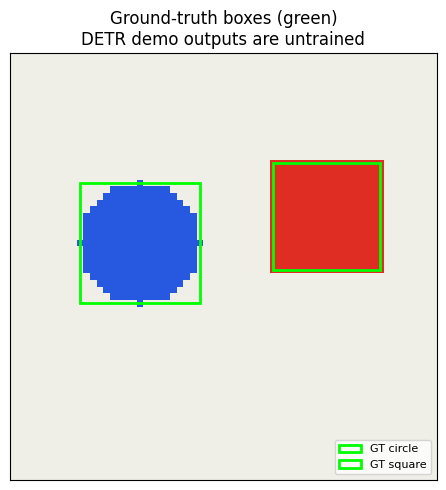

In [65]:
# Одно искусственное изображение 64×64 с двумя объектами.
img64 = np.zeros((64, 64, 3), dtype=np.float32); img64[:] = [0.94, 0.94, 0.91]
yy64, xx64 = np.mgrid[0:64, 0:64]
img64[(xx64 - 19)**2 + (yy64 - 28)**2 <= 9**2] = [0.15, 0.35, 0.88]  # круг
img64[(xx64 >= 39) & (xx64 <= 55) & (yy64 >= 16) & (yy64 <= 32)] = [0.88, 0.18, 0.14]  # квадрат
image_detr = torch.from_numpy(img64).permute(2, 0, 1).unsqueeze(0).to(device)
# xyxy в пикселях: круг (10,19)-(28,37), квадрат (39,16)-(55,32); переводим в нормализованные cxcywh.
gt_boxes_xyxy = torch.tensor([[10, 19, 28, 37], [39, 16, 55, 32]], dtype=torch.float32, device=device) / 64
gt_boxes_cxcywh = torch.stack([
    (gt_boxes_xyxy[:, 0] + gt_boxes_xyxy[:, 2]) / 2,
    (gt_boxes_xyxy[:, 1] + gt_boxes_xyxy[:, 3]) / 2,
    gt_boxes_xyxy[:, 2] - gt_boxes_xyxy[:, 0],
    gt_boxes_xyxy[:, 3] - gt_boxes_xyxy[:, 1],
], dim=-1)
target_one = {"labels": torch.tensor([0, 1], dtype=torch.long, device=device), "boxes": gt_boxes_cxcywh}

with torch.no_grad():
    outputs_one = detr_demo(image_detr)
q_idx, gt_idx = hungarian_match(outputs_one["pred_logits"][0], outputs_one["pred_boxes"][0], target_one)
print("Матчинг (query → GT):", list(zip(q_idx.tolist(), gt_idx.tolist())))

lambda_box = 5.0
lambda_giou = 2.0

losses_one = detr_set_loss(outputs_one, [target_one], num_classes=2)

print(f"Classification: {losses_one['loss_class'].item():.4f}")
print(f"Box L1:         {losses_one['loss_box'].item():.4f} "
      f"× {lambda_box} = "
      f"{lambda_box * losses_one['loss_box'].item():.4f}")
print(f"GIoU:           {losses_one['loss_giou'].item():.4f} "
      f"× {lambda_giou} = "
      f"{lambda_giou * losses_one['loss_giou'].item():.4f}")
print("-" * 45)
print(f"Total loss:     {losses_one['loss'].item():.4f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img64)
for box, label in zip(gt_boxes_xyxy.cpu().numpy(), ["GT circle", "GT square"]):
    x1, y1, x2, y2 = box * 64
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="lime", linewidth=2, label=label))
ax.set_title("Ground-truth boxes (green)\nDETR demo outputs are untrained")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

Step   1/300: loss=7.0597, class=1.1759, box=0.8135, giou=0.9081
Step  50/300: loss=1.9629, class=0.3866, box=0.1730, giou=0.3555
Step 100/300: loss=0.3506, class=0.2381, box=0.0097, giou=0.0319
Step 150/300: loss=0.2492, class=0.1735, box=0.0052, giou=0.0250
Step 200/300: loss=0.1876, class=0.1344, box=0.0044, giou=0.0155
Step 250/300: loss=0.1699, class=0.1068, box=0.0046, giou=0.0201
Step 300/300: loss=0.1218, class=0.0827, box=0.0034, giou=0.0109


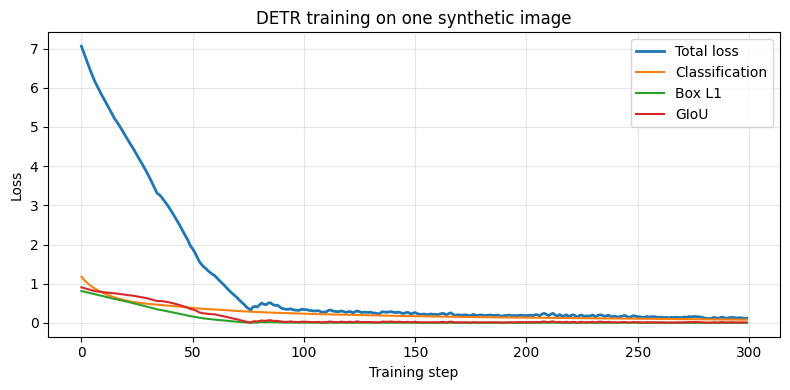

In [66]:
# Обучаем текущую модель на одном искусственном изображении.
# Цель — увидеть, как уменьшается set loss и улучшаются предсказания.

optimizer = torch.optim.AdamW(
    detr_demo.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

num_steps = 300

history = {
    "loss": [],
    "loss_class": [],
    "loss_box": [],
    "loss_giou": []
}

for step in range(num_steps):
    detr_demo.train()
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    outputs_step = detr_demo(image_detr)

    # Hungarian matching + set loss
    losses = detr_set_loss(
        outputs_step,
        [target_one],
        num_classes=2
    )

    # Backpropagation
    losses["loss"].backward()

    # Ограничиваем величину градиента для стабильности обучения.
    torch.nn.utils.clip_grad_norm_(
        detr_demo.parameters(),
        max_norm=0.1
    )

    optimizer.step()

    # Сохраняем значения loss для построения графика.
    for name in history:
        history[name].append(losses[name].item())

    if step == 0 or (step + 1) % 50 == 0:
        print(
            f"Step {step + 1:3d}/{num_steps}: "
            f"loss={losses['loss'].item():.4f}, "
            f"class={losses['loss_class'].item():.4f}, "
            f"box={losses['loss_box'].item():.4f}, "
            f"giou={losses['loss_giou'].item():.4f}"
        )

# Визуализируем динамику обучения.
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(history["loss"], label="Total loss", linewidth=2)
ax.plot(history["loss_class"], label="Classification")
ax.plot(history["loss_box"], label="Box L1")
ax.plot(history["loss_giou"], label="GIoU")

ax.set_xlabel("Training step")
ax.set_ylabel("Loss")
ax.set_title("DETR training on one synthetic image")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Предсказания модели после обучения:
Query 1: No-object  probability=0.881, box=[0.575 0.455 0.213 0.376]
Query 2: Square     probability=0.953, box=[0.734 0.375 0.251 0.25 ]
Query 3: No-object  probability=0.648, box=[0.479 0.405 0.286 0.341]
Query 4: No-object  probability=0.766, box=[0.607 0.477 0.254 0.357]
Query 5: Circle     probability=0.943, box=[0.297 0.439 0.284 0.282]


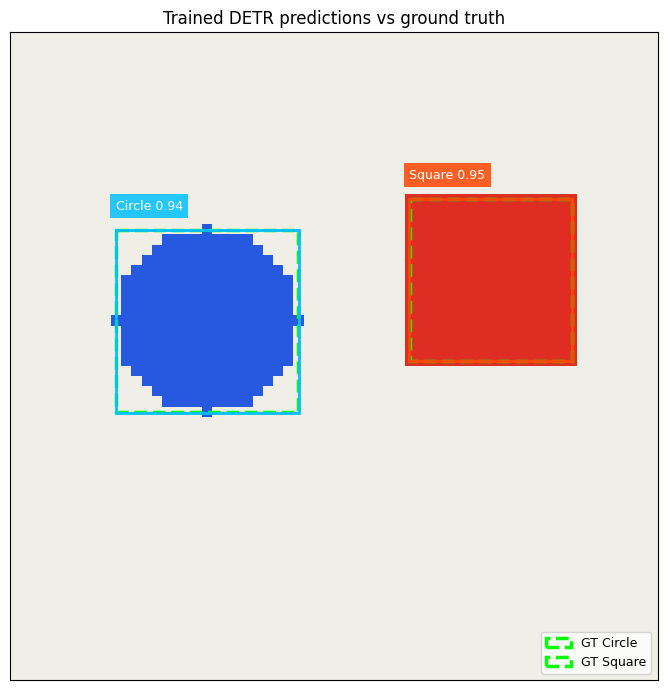


Количество найденных объектов: 2


In [67]:
detr_demo.eval()

with torch.inference_mode():
    trained_outputs = detr_demo(image_detr)

    # Вероятности классов для каждого query.
    probabilities = trained_outputs["pred_logits"][0].softmax(dim=-1)

    # Наиболее вероятный класс и его вероятность.
    scores, pred_labels = probabilities.max(dim=-1)

    # Предсказанные bounding boxes в формате cxcywh.
    pred_boxes = trained_outputs["pred_boxes"][0]

class_names = ["Circle", "Square", "No-object"]

# Покажем все пять queries, включая no-object.
print("Предсказания модели после обучения:")

for i in range(len(pred_labels)):
    label = pred_labels[i].item()
    box = pred_boxes[i].cpu().numpy()

    print(
        f"Query {i + 1}: "
        f"{class_names[label]:10s} "
        f"probability={scores[i].item():.3f}, "
        f"box={box.round(3)}"
    )

# Отбираем foreground-предсказания.
keep = (pred_labels != 2) & (scores > 0.5)

pred_boxes_xyxy = box_cxcywh_to_xyxy(pred_boxes[keep])
pred_boxes_xyxy = pred_boxes_xyxy.cpu().numpy() * 64

pred_labels_np = pred_labels[keep].cpu().numpy()
pred_scores_np = scores[keep].cpu().numpy()

# Визуализация GT и предсказаний.
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(img64)

# Ground-truth boxes: зелёные пунктирные рамки.
for box, label in zip(
    gt_boxes_xyxy.cpu().numpy() * 64,
    ["GT Circle", "GT Square"]
):
    x1, y1, x2, y2 = box

    ax.add_patch(
        plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2.5,
            linestyle="--",
            label=label
        )
    )

# Predicted boxes: цвет зависит от класса.
class_colors = {
    0: "deepskyblue",
    1: "orangered"
}

for box, label, score in zip(
    pred_boxes_xyxy,
    pred_labels_np,
    pred_scores_np
):
    x1, y1, x2, y2 = box
    color = class_colors[int(label)]

    ax.add_patch(
        plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False,
            edgecolor=color,
            linewidth=2
        )
    )

    ax.text(
        x1, max(y1 - 2, 1),
        f"{class_names[label]} {score:.2f}",
        color="white",
        fontsize=9,
        bbox=dict(facecolor=color, alpha=0.85, edgecolor="none")
    )

ax.set_title("Trained DETR predictions vs ground truth")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

print(f"\nКоличество найденных объектов: {keep.sum().item()}")

### 5.7. Что DETR меняет относительно anchor-based detection

| Компонент | Типичный anchor-based detector | DETR |
|---|---|---|
| Кандидаты | anchors / точки feature map | фиксированное число object queries |
| Сопоставление GT | matching anchors по IoU/правилам | Hungarian matching между queries и GT |
| Дубликаты | подавляются NMS | set loss поощряет уникальные назначения |
| Выход | много кандидатов с последующей фильтрацией | конечный набор predictions |
| Глобальный контекст | зависит от архитектуры backbone/neck | Transformer encoder/decoder явно смешивает контекст |

**Оговорка:** «DETR без NMS» относится к принципу оригинальной модели: set-based matching обучает queries предсказывать уникальные объекты. Это не означает, что все современные detector-модели используют один и тот же pipeline. Последующие варианты DETR меняли backbone, matching, multiscale features и обучение.

## Итог семинара 9

1. **Patchification** группирует пиксели в патчи и превращает двумерное изображение в последовательность токенов `(B, N, D)`.
2. **ViT** добавляет positional embeddings и `[CLS]`, после чего использует обычный Transformer encoder.
3. **CLIP** учит image и text embeddings в одном пространстве; similarity matrix и symmetric InfoNCE loss сближают правильные пары.
4. **Image–text retrieval** — поиск ближайшего текста или изображения по cosine similarity между нормализованными embeddings.
5. **DETR** предсказывает множество slots; Hungarian matching сопоставляет их с неупорядоченным набором GT объектов один-к-одному.





# Семинар 10. Autoregressive models, MADE и PixelCNN

## 6. Autoregressive factorization: от next-token prediction к распределению над вектором


### 6.1. Как научить нейросеть генерировать данные?

До этого мы рассматривали модели, которые получают входные данные и выдают предсказание. Например, Transformer предсказывает следующий токен текста.

Теперь поставим другую задачу: **мы хотим, чтобы нейросеть сама создавала новые данные**, похожие на те, на которых она обучалась.

Например, модель может генерировать текст или изображения. Но как это сделать?

Представим, что мы хотим создать новое изображение. Оно состоит из множества пикселей, и нам нужно определить значение каждого из них.

Можно было бы генерировать каждый пиксель независимо, но тогда мы получили бы случайный набор цветных точек. Чтобы изображение имело смысл, пиксели должны зависеть друг от друга.

Одна из идей — **генерировать данные последовательно**:

1. Сначала модель генерирует первый элемент.
2. Затем генерирует второй, учитывая первый.
3. Генерирует третий, учитывая первые два.
4. Продолжает, пока не сформирует весь объект.

Например, если нужно сгенерировать последовательность из трёх бинарных значений (0 или 1), процесс может выглядеть так:

```text
Шаг 1: генерируем x₁
       ↓
Шаг 2: генерируем x₂, учитывая x₁
       ↓
Шаг 3: генерируем x₃, учитывая x₁ и x₂
       ↓
Результат: [1, 0, 1]
```

Чтобы реализовать такой процесс, модель должна научиться отвечать на вопросы:

- С какой вероятностью первый элемент равен 1?
- Какова вероятность, что второй элемент равен 0, если первый уже равен 1?
- Какова вероятность, что третий элемент равен 1, если первые два равны 1 и 0?

Именно на этой идее основаны **авторегрессионные модели** (*autoregressive models*).

### 6.2. Как вычислить вероятность всей последовательности?

Допустим, мы хотим узнать, насколько вероятна конкретная последовательность:

$$
\mathbf{x} = (x_1, x_2, x_3).
$$

Вместо того чтобы сразу оценивать вероятность всей последовательности, можно вычислить вероятности отдельных элементов, учитывая уже известные предыдущие элементы:

$$
\boxed{
p(x_1,x_2,x_3) =
p(x_1)\cdot
p(x_2\mid x_1)\cdot
p(x_3\mid x_1,x_2)
}
$$

Это следует из **chain rule** (правила умножения вероятностей).

Например, для последовательности `[1, 0, 1]`:

$$
\begin{aligned}
p(1,0,1) ={}&
p(x_1=1) \cdot \\
& p(x_2=0\mid x_1=1) \cdot \\
& p(x_3=1\mid x_1=1,x_2=0).
\end{aligned}
$$

Таким образом, вероятность всей последовательности равна произведению вероятностей отдельных шагов генерации.

Для вектора произвольной длины $D$:

$$
p(\mathbf{x}) =
\prod_{d=1}^{D} p(x_d\mid x_1,\ldots,x_{d-1}).
$$

Это называется **autoregressive factorization** — разложение совместного распределения на последовательность условных распределений.

### 6.3. Как это связано с Transformer, MADE и PixelCNN?

Все эти архитектуры используют одну и ту же основную идею: предсказывают очередной элемент с учётом предыдущих.

Различие заключается в том, какие данные они генерируют и как организуют вычисления:

| Модель | Что генерирует | На что опирается |
|---|---|---|
| Autoregressive Transformer | Текст | Предыдущие токены |
| MADE | Вектор признаков | Предыдущие компоненты вектора |
| PixelCNN | Изображения | Предыдущие пиксели |

Далее разберём, как реализовать такую зависимость в нейросетях с помощью масок и специальных архитектур.

**Главное:** авторегрессионное разложение — не приближение и не особый трюк нейросетей. Это точное математическое представление совместной вероятности. А вот научиться оценивать каждую условную вероятность с помощью нейросети — уже задача машинного обучения.


### 6.3. Likelihood и обучение

Для одного наблюдаемого вектора логарифм вероятности равен сумме логарифмов условных вероятностей:

$$
\log p(\mathbf{x}) = \sum_{d=1}^{D}\log p(x_d\mid x_{<d}).
$$

Поэтому обучение максимизацией likelihood эквивалентно минимизации negative log-likelihood (NLL):

$$
\mathcal L_{NLL} = -\sum_{d=1}^{D}\log p(x_d\mid x_{<d}).
$$

Для бинарной переменной каждая условная вероятность задаётся числом `p_d = sigmoid(logit_d)`, и NLL превращается в Binary Cross-Entropy. Это ровно знакомая BCE, но теперь каждый выходной logit отвечает за вероятность очередного элемента вектора с условием на предыдущие элементы.

In [21]:
# Численный пример: четыре бинарные переменные и их условные вероятности.
x_example = [1, 0, 1, 1]
conditional_probs = [0.70, 0.20, 0.85, 0.60]  # P(x_d=1 | предыдущие значения)
terms = []
for x_d, p_d in zip(x_example, conditional_probs):
    p_observed = p_d if x_d == 1 else 1 - p_d
    terms.append(p_observed)
joint_probability = float(np.prod(terms))
print("Наблюдение x:", x_example)
print("Вероятности наблюдённых значений:", np.round(terms, 3))
print(f"p(x) = произведение условных вероятностей = {joint_probability:.5f}")
print(f"log p(x) = {math.log(joint_probability):.4f}")
print(f"NLL = {-math.log(joint_probability):.4f}")

Наблюдение x: [1, 0, 1, 1]
Вероятности наблюдённых значений: [0.7  0.8  0.85 0.6 ]
p(x) = произведение условных вероятностей = 0.28560
log p(x) = -1.2532
NLL = 1.2532


### 6.4. Почему нельзя просто подать весь вектор в обычный MLP

Если обычный MLP получает весь вектор `x` и одновременно предсказывает все компоненты, выход `d` может использовать не только `x_1,...,x_{d-1}`, но и `x_d` или будущие `x_{d+1},...`. В результате модель может «подсмотреть» правильный ответ, а выход уже нельзя честно интерпретировать как `p(x_d | x_<d)`.

Нужно гарантировать структурно:

- выход для `x_1` не зависит от входных данных;
- выход для `x_2` зависит только от `x_1`;
- выход для `x_3` зависит только от `x_1,x_2`;
- и так далее.

В языковой модели это делала causal mask в attention. **MADE** добивается того же с помощью масок весов обычных линейных слоёв.

## 7. MADE: Masked Autoencoder for Distribution Estimation

### 7.1. Идея MADE

MADE — это MLP, у которого часть весов принудительно обнулена. Маски устроены так, чтобы выход для `x_d` мог зависеть только от предыдущих входных компонент.

Название *autoencoder* историческое: сеть получает вектор `x` и выдаёт по одному предсказанию для каждой его компоненты. Но это не обычный autoencoder, который восстанавливает вход из сжатого представления. Здесь маски делают каждый выход условным предсказанием, а loss становится корректным NLL совместного распределения.

### 7.2. Нумеруем переменные и скрытые нейроны

Пронумеруем входные переменные числами от `1` до `D`. Каждому hidden neuron тоже назначим целое число — **degree** — от `1` до `D−1`. Degree определяет, какую максимальную входную позицию скрытый нейрон может видеть.

Например, hidden neuron с degree `2` может получать информацию от `x_1` и `x_2`, но не от `x_3` и далее.

Для слоя от входа к hidden используем условие:

$$
M^{(1)}_{h,i} = \mathbb{1}[m_i^{input} \le m_h^{hidden}].
$$

Для связей между hidden-слоями разрешаем соединение, если degree не уменьшается:

$$
M^{(l)}_{j,i} = \mathbb{1}[m_i^{(l)} \le m_j^{(l+1)}].
$$

Для последнего слоя, который выдаёт logits переменных `x_1,...,x_D`, используем **строгое** неравенство:

$$
M^{(out)}_{d,h} = \mathbb{1}[m_h^{hidden} < m_d^{output}].
$$

Почему последнее строгое? Если degree hidden neuron равен `d`, он уже может видеть `x_d`; значит его нельзя подключать к выходу, предсказывающему `x_d`. Строгое ` < ` удаляет такую утечку.


### 7.3. Какие зависимости разрешены в MADE?

Рассмотрим пять входных переменных и соответствующие им выходы:

- `x₁, ..., x₅` — входные значения;
- `y₁, ..., y₅` — выходные logits, предсказывающие вероятности соответствующих переменных.

Каждый выход может зависеть только от предыдущих входов:

```text
x₁ ─────────┬──────→ y₂
            ├──────→ y₃
            ├──────→ y₄
            └──────→ y₅

x₂ ─────────┬──────→ y₃
            ├──────→ y₄
            └──────→ y₅

x₃ ─────────┬──────→ y₄
            └──────→ y₅

x₄ ─────────────────→ y₅

x₅ ── нет разрешённых связей с выходами
```

То же самое можно представить в виде матрицы зависимостей:

| Выход ↓ / Вход → | x₁ | x₂ | x₃ | x₄ | x₅ |
|:---|:---:|:---:|:---:|:---:|:---:|
| **y₁** | — | — | — | — | — |
| **y₂** | ✓ | — | — | — | — |
| **y₃** | ✓ | ✓ | — | — | — |
| **y₄** | ✓ | ✓ | ✓ | — | — |
| **y₅** | ✓ | ✓ | ✓ | ✓ | — |

Здесь `✓` означает, что связь разрешена, а `—` — что связь запрещена.

Например:
- `y₁` не зависит ни от одного входа;
- `y₂` зависит только от `x₁`;
- `y₃` зависит от `x₁` и `x₂`;
- `y₄` зависит от `x₁`, `x₂` и `x₃`;
- `y₅` зависит от `x₁`, `x₂`, `x₃` и `x₄`.

**Почему это важно?**

Каждый выход `y_d` должен предсказывать условную вероятность:

$$
p(x_d \mid x_1, \ldots, x_{d-1}).
$$

Поэтому запрещены две группы связей:

1. Связь `x_d → y_d`: переменная не должна использовать собственное значение для предсказания.
2. Связи от будущих переменных `x_{d+1}, ..., x_D` к `y_d`: будущая информация недоступна при генерации текущей переменной.

Именно такое ограничение позволяет MADE моделировать авторегрессионное распределение.

### 7.4. MaskedLinear: слой, который не может использовать запрещённые связи

Обычный `nn.Linear` вычисляет `x @ W.T + b`. В `MaskedLinear` мы храним бинарную матрицу `mask` той же формы, что и `W`, и в forward используем `W * mask`. Запрещённые веса всегда умножаются на ноль.

Маску регистрируем как `buffer`: она сохраняется в `state_dict`, переносится на GPU вместе с моделью, но не обучается оптимизатором. Сам вес остаётся обучаемым.

In [ ]:

[ 0 1 
1 0

]

In [68]:
class MaskedLinear(nn.Module):
    def __init__(self, in_features, out_features, mask):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.register_buffer("mask", mask.to(dtype=torch.float32))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))

    def forward(self, x):
        return F.linear(x, self.weight * self.mask, self.bias)

class MADE(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=128, n_hidden_layers=2, seed=0):
        super().__init__()
        if input_dim < 2:
            raise ValueError("Для MADE нужно input_dim >= 2")
        self.input_dim = input_dim
        input_degrees = torch.arange(1, input_dim + 1)
        rng = torch.Generator().manual_seed(seed)
        hidden_degrees = [
            torch.randint(1, input_dim, (hidden_dim,), generator=rng)
            for _ in range(n_hidden_layers)
        ]
        layers = []
        first_mask = (hidden_degrees[0][:, None] >= input_degrees[None, :])
        layers.append(MaskedLinear(input_dim, hidden_dim, first_mask))
        for prev_deg, next_deg in zip(hidden_degrees[:-1], hidden_degrees[1:]):
            mask = next_deg[:, None] >= prev_deg[None, :]
            layers.append(MaskedLinear(hidden_dim, hidden_dim, mask))
        output_degrees = input_degrees
        last_mask = (output_degrees[:, None] > hidden_degrees[-1][None, :])
        layers.append(MaskedLinear(hidden_dim, input_dim, last_mask))
        self.layers = nn.ModuleList(layers)

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = F.relu(layer(x))
        return self.layers[-1](x)  # logits: (B, D), один Bernoulli-logit на переменную

made_demo = MADE(input_dim=8, hidden_dim=32, n_hidden_layers=2).to(device)
with torch.no_grad():
    made_logits = made_demo(torch.randint(0, 2, (3, 8), device=device).float())
print("Вход:", (3, 8), "Выход MADE:", tuple(made_logits.shape))
print("Маски слоёв:", [tuple(layer.mask.shape) for layer in made_demo.layers])

Вход: (3, 8) Выход MADE: (3, 8)
Маски слоёв: [(32, 8), (32, 32), (8, 32)]


### 7.5. Проверим отсутствие утечки через Jacobian

Архитектурная гарантия должна быть проверяема. Посчитаем матрицу производных

$$
J_{d,i} = \frac{\partial\,logit_d}{\partial x_i}.
$$

Если MADE реализован правильно, `logit_d` не зависит от `x_d` и от будущих компонент `x_{d+1},...,x_D`. Поэтому диагональ и элементы выше диагонали Jacobian должны быть нулевыми (или численно очень близкими к нулю). Нижняя часть может быть ненулевой: более поздние outputs могут зависеть от ранних inputs.

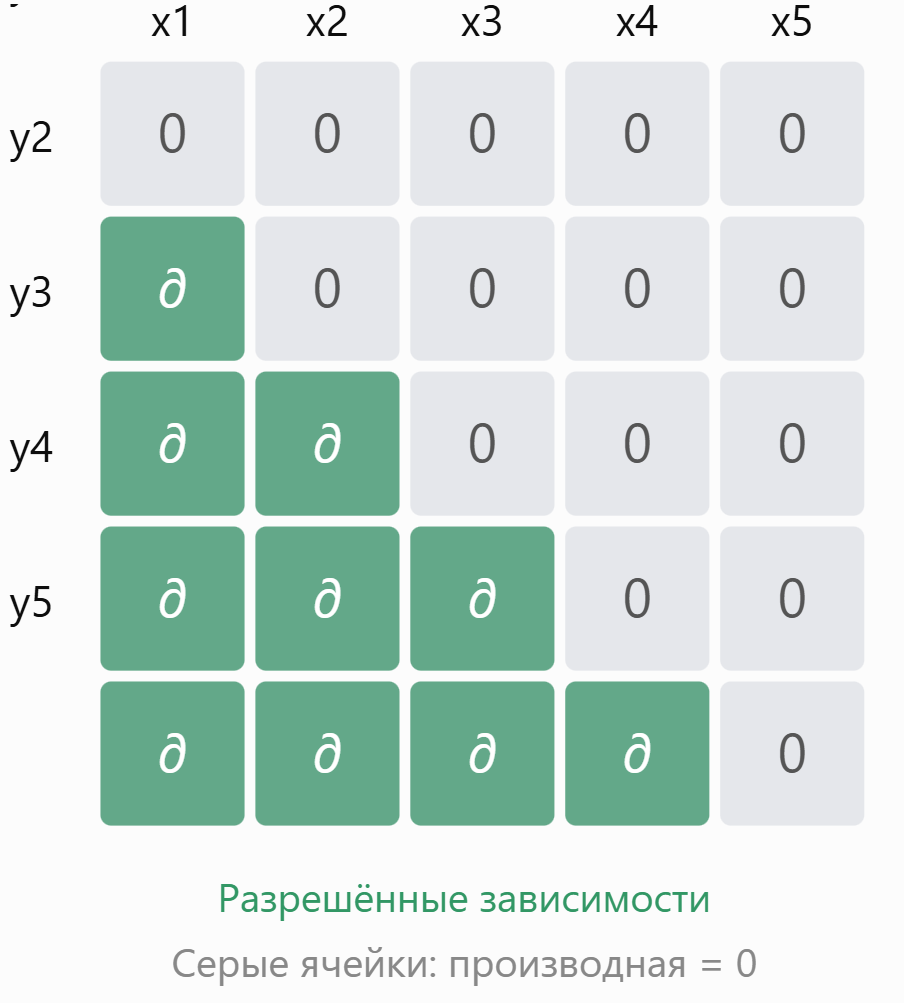

Максимум |J| на диагонали и выше: 0.0


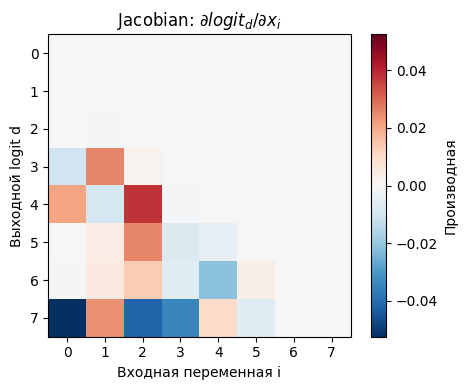

In [69]:
x_jac = torch.rand(8, device=device, requires_grad=True)

def made_single_output(x):
    return made_demo(x.unsqueeze(0)).squeeze(0)

jac = torch.autograd.functional.jacobian(
    made_single_output, x_jac
).detach().cpu().numpy()

print("Максимум |J| на диагонали и выше:", np.abs(np.triu(jac)).max())

# Симметричная шкала относительно нуля.
vmax = max(np.abs(jac).max(), 1e-12)

fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(
    jac,
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
    aspect="equal"
)

ax.set_xlabel("Входная переменная i")
ax.set_ylabel("Выходной logit d")
ax.set_title(r"Jacobian: $\partial logit_d / \partial x_i$")
ax.set_xticks(range(8))
ax.set_yticks(range(8))

fig.colorbar(im, ax=ax, label="Производная")
plt.tight_layout()
plt.show()

assert np.abs(np.triu(jac)).max() < 1e-7

## 8. Обучаем MADE оценивать совместное распределение

### 8.1. Синтетическое распределение с зависимостями

Чтобы проверить модель, сгенерируем бинарные последовательности длины `D=8` по известному правилу:

- `x₁` — равновероятный ноль или единица;
- каждый следующий бит с вероятностью `0.95` повторяет предыдущий и с вероятностью `0.05` меняется.

Таким образом, соседние переменные сильно зависимы. Если мы моделируем каждую координату независимо, то теряем информацию о предыдущем бите. Autoregressive модель должна научиться использовать эту зависимость.

В реальных задачах истинное правило неизвестно — доступны только наблюдения. Здесь синтетическое распределение нужно для того, чтобы результат можно было интерпретировать.

In [36]:
def sample_chain_dataset(n_samples, dim=8, flip_prob=0.05, seed=0):
    rng = np.random.default_rng(seed)
    x = np.zeros((n_samples, dim), dtype=np.float32)
    x[:, 0] = rng.integers(0, 2, size=n_samples)
    for d in range(1, dim):
        flip = rng.random(n_samples) < flip_prob
        x[:, d] = np.where(flip, 1 - x[:, d-1], x[:, d-1])
    return torch.from_numpy(x)

D = 8
train_data = sample_chain_dataset(6000, dim=D, seed=1)
valid_data = sample_chain_dataset(2000, dim=D, seed=2)
print("Train:", tuple(train_data.shape), "Validation:", tuple(valid_data.shape))
print("Первые 12 последовательностей:")
print(train_data[:12].int().numpy())

Train: (6000, 8) Validation: (2000, 8)
Первые 12 последовательностей:
[[0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [0 0 0 1 1 1 1 1]
 [0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1]
 [0 0 1 1 1 1 1 1]]


### 8.2. Bernoulli likelihood = BCEWithLogitsLoss

MADE выдаёт один logit на каждую координату. После sigmoid получаем вероятность `p(x_d=1 | x_<d)`. Для бинарного значения `x_d` отрицательный логарифм вероятности равен

$$
-\log p(x_d\mid x_{<d}) =
-x_d\log p_d -(1-x_d)\log(1-p_d).
$$

Это binary cross-entropy. Складываем её по всем координатам, затем усредняем по объектам. В отличие от обычной бинарной классификации, каждый logit относится к отдельной позиции в совместном распределении.

Время обучения: 4.0 с на cpu
Validation NLL: 4.649 → 2.090 nats / vector


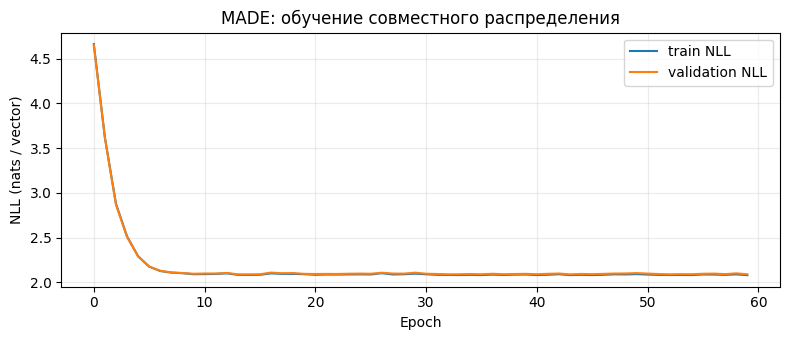

In [ ]:
made = MADE(input_dim=D, hidden_dim=128, n_hidden_layers=2, seed=42).to(device)
optimizer_made = torch.optim.AdamW(made.parameters(), lr=3e-3, weight_decay=1e-5)

def batch_nll(model, batch):
    logits = model(batch)
    return F.binary_cross_entropy_with_logits(logits, batch, reduction="none").sum(dim=1).mean()

@torch.no_grad()
def evaluate_nll(model, data, batch_size=512):
    model.eval()
    values = []
    for start in range(0, len(data), batch_size):
        batch = data[start:start+batch_size].to(device)
        values.append(batch_nll(model, batch).item())
    return float(np.mean(values))

made_epochs = 60
made_batch_size = 256
made_history = []
start_time = time.time()
for epoch in range(made_epochs):
    made.train()
    permutation = torch.randperm(len(train_data))
    for start in range(0, len(train_data), made_batch_size):
        idx = permutation[start:start+made_batch_size]
        batch = train_data[idx].to(device)
        optimizer_made.zero_grad(set_to_none=True)
        loss = batch_nll(made, batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(made.parameters(), max_norm=2.0)
        optimizer_made.step()
    train_nll = evaluate_nll(made, train_data)
    valid_nll = evaluate_nll(made, valid_data)
    made_history.append((train_nll, valid_nll))
print(f"Время обучения: {time.time() - start_time:.1f} с на {device}")
print(f"Validation NLL: {made_history[0][1]:.3f} → {made_history[-1][1]:.3f} nats / vector")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([x[0] for x in made_history], label="train NLL")
ax.plot([x[1] for x in made_history], label="validation NLL")
ax.set_xlabel("Epoch"); ax.set_ylabel("NLL (nats / vector)")
ax.set_title("MADE: обучение совместного распределения")
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### 8.3. Сравним с независимой моделью

Независимая модель оценивает `p(x) = ∏_d p(x_d)` и не учитывает контекст `x_<d`. В нашем наборе каждый отдельный бит примерно равновероятен, поэтому независимый baseline будет отдавать вероятность около `0.5` каждому значению. Он не сможет использовать почти детерминированную зависимость между соседними битами.

Для бинарного распределения с вероятностью `0.5` NLL одной координаты равна `ln 2`; на вектор длины 8 baseline ожидаемо даёт около `8 ln 2 ≈ 5.545` nats. MADE должен получить меньше, используя зависимость.

In [38]:
# Независимый baseline: вероятность единицы оценивается отдельно по каждой координате.
# Для симметричной цепочки все координаты имеют маргинальную вероятность около 0.5.
with torch.no_grad():
    marginal_p = train_data.mean(dim=0).to(device).clamp(1e-5, 1 - 1e-5)
    baseline_nll = -(
        valid_data.to(device) * marginal_p.log()
        + (1 - valid_data.to(device)) * (1 - marginal_p).log()
    ).sum(dim=1).mean().item()
    made_valid_nll = evaluate_nll(made, valid_data)
print(f"Independent baseline NLL: {baseline_nll:.3f} nats / vector")
print(f"MADE validation NLL:      {made_valid_nll:.3f} nats / vector")
print("Чем меньше NLL, тем большую вероятность модель в среднем назначает наблюдаемым векторам.")

Independent baseline NLL: 5.545 nats / vector
MADE validation NLL:      2.090 nats / vector
Чем меньше NLL, тем большую вероятность модель в среднем назначает наблюдаемым векторам.


## 9. Ancestral sampling: генерируем вектор по одному элементу

### 9.1. От условных вероятностей к сэмплу

После обучения MADE мы можем оценить вероятность любого полного вектора: запускаем сеть один раз и получаем все условные вероятности параллельно. Но **генерация** устроена последовательно:

1. Сначала сэмплируем `x₁ ~ p(x₁)`.
2. Затем `x₂ ~ p(x₂ | x₁)`.
3. Затем `x₃ ~ p(x₃ | x₁,x₂)`.
4. Продолжаем, пока не заполним весь вектор.

Такой способ называется **ancestral sampling** (сэмплирование по цепочке условных распределений). Мы генерируем каждую следующую переменную из распределения, параметры которого зависят от уже сгенерированной части.

Почему нельзя сгенерировать все координаты одновременно? Потому что для `x₄` нужно знать `x₁,x₂,x₃`, а они сами только что были сэмплированы. В отличие от likelihood evaluation, при генерации зависимые переменные не доступны заранее.

Сгенерированные последовательности:
[[1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0]
 [1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 1]
 [1 1 1 1 0 0 1 1]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0]
 [1 1 1 1 1 1 1 1]]


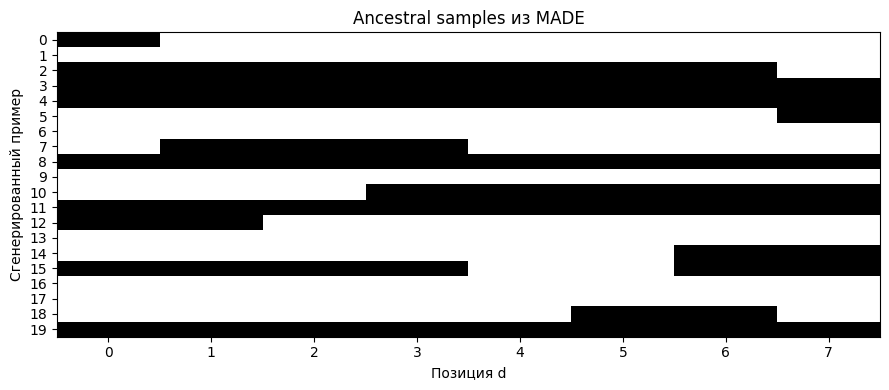

In [70]:
@torch.inference_mode()
def ancestral_sample_made(model, n_samples, dim, device=device):
    model.eval()
    samples = torch.zeros(n_samples, dim, device=device)
    for d in range(dim):
        logits = model(samples)
        probabilities = torch.sigmoid(logits[:, d])
        samples[:, d] = torch.bernoulli(probabilities)
    return samples.cpu()

samples_made = ancestral_sample_made(made, n_samples=20, dim=D)
print("Сгенерированные последовательности:")
print(samples_made.int().numpy())

fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(samples_made.numpy(), cmap="Greys", vmin=0, vmax=1, aspect="auto")
ax.set_xlabel("Позиция d"); ax.set_ylabel("Сгенерированный пример")
ax.set_title("Ancestral samples из MADE")
ax.set_xticks(range(D)); ax.set_yticks(range(20))
plt.tight_layout(); plt.show()

### 9.2. Сверим статистику генерации с правилом данных

Для исходной цепочки вероятность смены бита была `0.05`. Поэтому соседние элементы обычно равны. Посчитаем долю переходов между 0 и 1 в реальных и сгенерированных последовательностях.

In [71]:
def flip_rate(data):
    return (data[:, 1:] != data[:, :-1]).float().mean().item()

samples_large = ancestral_sample_made(made, n_samples=2000, dim=D)
print(f"Flip rate в validation: {flip_rate(valid_data):.3f}")
print(f"Flip rate в MADE samples: {flip_rate(samples_large):.3f}")
print("Теоретическое значение для исходного генератора: 0.05")

Flip rate в validation: 0.050
Flip rate в MADE samples: 0.056
Теоретическое значение для исходного генератора: 0.05


### ➕ Дополнение: temperature при ancestral sampling

Для Bernoulli-модели temperature можно применить к logits перед sigmoid: `sigmoid(logit / T)`. Маленькая `T` делает вероятности ближе к 0 или 1, большая — ближе к 0.5. Но это уже изменяет выученное распределение: при `T != 1` сэмплы не являются выборкой из исходной модели с точностью до численной погрешности.

In [82]:
@torch.inference_mode()
def ancestral_sample_temperature(model, n_samples, dim, temperature=1.0):
    if temperature <= 0:
        raise ValueError("temperature должна быть > 0")
    model.eval()
    samples = torch.zeros(n_samples, dim, device=device)
    for d in range(dim):
        logits = model(samples)[:, d] / temperature
        samples[:, d] = torch.bernoulli(torch.sigmoid(logits))
    return samples.cpu()

for temperature in [0.5, 1.0, 2.0]:
    s = ancestral_sample_temperature(made, 1000, D, temperature)
    print(f"temperature={temperature:.1f}: flip rate={flip_rate(s):.3f}")

temperature=0.5: flip rate=0.003
temperature=1.0: flip rate=0.051
temperature=2.0: flip rate=0.197


## 10. PixelCNN: autoregressive factorization для изображений

### 10.1. От вектора к двумерной сетке

MADE выше работал с вектором. Но изображение тоже можно превратить в последовательность, если выбрать порядок обхода пикселей. Обычно используется **raster scan**: слева направо, сверху вниз.

Для пикселя в позиции `(row, col)` допустимая информация — это:

- все пиксели в предыдущих строках;
- пиксели слева в текущей строке;
- но не сам текущий пиксель и не пиксели справа или ниже.

Тогда:

$$
p(\text{image}) = \prod_{r=1}^{H}\prod_{c=1}^{W}
 p(x_{r,c}\mid x_{\text{все предыдущие пиксели}}).
$$

Это тот же autoregressive factorization, только порядок задан двумерной координатной сеткой.

### 10.2. Masked convolutions

Обычная свёртка смотрит на пиксели вокруг текущего положения во все стороны. Для autoregressive-модели это нарушает порядок: свёртка могла бы использовать будущие пиксели. PixelCNN решает это маской весов ядра: запрещённые позиции умножаются на ноль.

Используют два типа масок:

- **Mask A** — первая свёртка. Она запрещает использовать текущий пиксель и все будущие позиции.
- **Mask B** — последующие скрытые свёртки. Они могут использовать центральную позицию скрытой карты признаков, потому что эта карта уже была построена из допустимого прошлого. Но будущие позиции по-прежнему закрыты.

```text
Порядок raster scan для 4×4:
 0   1   2   3
 4   5   6   7
 8   9  10  11
12  13  14  15

Для предсказания пикселя 10 доступны:
 0  1  2  3
 4  5  6  7
 8  9  X  .
 .  .  .  .

X — текущий пиксель, точки — будущее; они недоступны.
```

В цветном изображении обычно задают ещё и порядок внутри пикселя: например, `R → G → B`, где `G` зависит от `R`, а `B` — от `R` и `G`. В нашей иллюстрации ниже рассматривается grayscale-случай, чтобы не перегружать объяснение каналами.

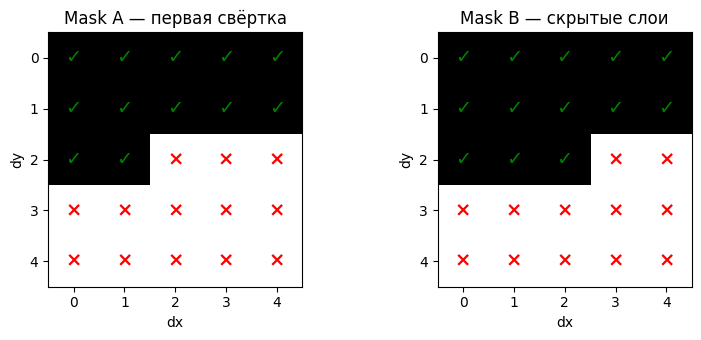

In [50]:
def make_spatial_mask(kernel_size=5, mask_type="A"):
    if kernel_size % 2 == 0:
        raise ValueError("kernel_size должен быть нечётным")
    if mask_type not in {"A", "B"}:
        raise ValueError("mask_type должен быть 'A' или 'B'")
    mask = torch.ones(kernel_size, kernel_size)
    center = kernel_size // 2
    mask[center + 1:, :] = 0       # все строки ниже центра — будущее
    mask[center, center + 1:] = 0  # справа от центра в текущей строке — будущее
    if mask_type == "A":
        mask[center, center] = 0  # текущий пиксель запрещён
    return mask

mask_a = make_spatial_mask(5, "A")
mask_b = make_spatial_mask(5, "B")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, mask, title in [(axes[0], mask_a, "Mask A — первая свёртка"), (axes[1], mask_b, "Mask B — скрытые слои")]:
    ax.imshow(mask.numpy(), cmap="Greys", vmin=0, vmax=1)
    ax.set_title(title); ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xlabel("dx"); ax.set_ylabel("dy")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, "✓" if mask[i,j] else "×", ha="center", va="center",
                    color="green" if mask[i,j] else "red", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

### 10.3. Реализуем MaskedConv2d и проверим градиентом

Вместо того чтобы менять архитектуру `Conv2d`, мы умножаем её веса на заранее созданную маску в каждом forward. Это аналог `MaskedLinear` из MADE.

Проверка будет такой: возьмём выход в центральной позиции и посчитаем его градиент по входному изображению. Если маскирование корректно, у текущего и будущих пикселей градиент должен быть нулевым.

Градиент по текущему пикселю: 0.0
Максимум градиента на будущих позициях (строки ниже + справа): 0.0


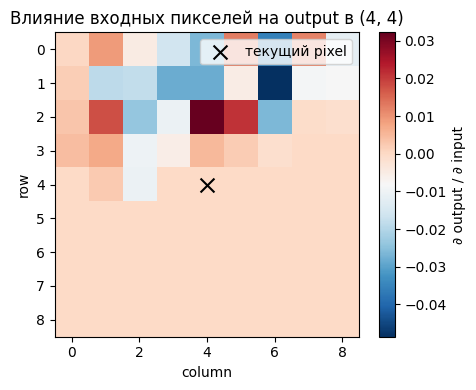

In [87]:
class MaskedConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=5, mask_type="A", padding=None):
        super().__init__()
        if isinstance(kernel_size, tuple):
            kh, kw = kernel_size
        else:
            kh = kw = kernel_size
        if kh != kw or kh % 2 == 0:
            raise ValueError("Для примера требуется квадратное нечётное ядро")
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kh,
                              padding=kh//2 if padding is None else padding)
        spatial_mask = make_spatial_mask(kh, mask_type)
        self.register_buffer("mask", spatial_mask[None, None].expand_as(self.conv.weight).clone())

    def forward(self, x):
        weight = self.conv.weight * self.mask
        return F.conv2d(x, weight, self.conv.bias,
                        stride=self.conv.stride, padding=self.conv.padding,
                        dilation=self.conv.dilation, groups=self.conv.groups)

# Первая свёртка A и последующая B.
conv_a = MaskedConv2d(1, 4, kernel_size=5, mask_type="A").to(device)
conv_b = MaskedConv2d(4, 1, kernel_size=5, mask_type="B").to(device)
input_pixels = torch.randn(1, 1, 9, 9, device=device, requires_grad=True)
hidden_pixels = F.relu(conv_a(input_pixels))
output_pixels = conv_b(hidden_pixels)
center_value = output_pixels[0, 0, 4, 4]
grad_input = torch.autograd.grad(center_value, input_pixels)[0][0, 0].detach().cpu().numpy()

print("Градиент по текущему пикселю:", grad_input[4, 4])
print("Максимум градиента на будущих позициях (строки ниже + справа):",
      max(np.abs(grad_input[5:, :]).max(), np.abs(grad_input[4, 4:]).max()))
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(grad_input, cmap="RdBu_r")
ax.scatter([4], [4], marker="x", s=100, color="black", label="текущий pixel")
ax.set_title("Влияние входных пикселей на output в (4, 4)")
ax.set_xlabel("column"); ax.set_ylabel("row"); ax.legend()
fig.colorbar(im, ax=ax, label="∂ output / ∂ input")
plt.tight_layout(); plt.show()

**Почему Mask B не нарушает autoregressive property?** Вторая свёртка может использовать центральный элемент своей входной карты признаков, но этот элемент уже вычислен первой свёрткой A. Первая свёртка не пропускает исходный текущий пиксель и будущее. Последующие B-слои смешивают только уже причинно допустимые признаки. Поэтому запрет обеспечивается всей цепочкой, а не тем, что каждая отдельная B-маска исключает центр.

### 10.4. MADE и PixelCNN — одна идея, разные слои

| Свойство | MADE | PixelCNN |
|---|---|---|
| Данные | Вектор `x₁,...,x_D` | Двумерная сетка пикселей |
| Порядок | Индексы `1 → D` | Raster scan, обычно строка за строкой |
| Слой | Полносвязный `Linear` | `Conv2d` |
| Ограничение | Маски весов по degree | Пространственная маска ядра |
| Обучение | NLL / BCE для условных вероятностей | NLL для дискретных значений пикселей |
| Генерация | По одной координате за шаг | По одному пикселю/каналу за шаг |

PixelCNN использует свёртки, поэтому одинаковые локальные фильтры применяются по всему изображению; это даёт эффективное параметрическое описание локальных зависимостей. Но генерация остаётся последовательной по выбранному порядку: чтобы сгенерировать следующий пиксель, нужно знать уже сгенерированные предыдущие.

**Ограничение:** в этом ноутбуке мы разобрали маски и проверили отсутствие утечки, но не обучали полноценный PixelCNN на изображениях. Для обучения потребуются большой набор картинок, выбор дискретизации каналов (например, 256 уровней), соответствующая выходная голова и существенно больше вычислений.

## Итог: что нужно унести с семинаров 9–10

1. **Patchification** — способ превратить изображение в последовательность неперекрывающихся патчей. После flatten и projection получаем `(B, N, D)`.
2. **ViT** — обычный Transformer encoder для последовательности патчей; positional embeddings сохраняют геометрию, `[CLS]` агрегирует изображение.
3. **CLIP** — два encoder-а отображают изображение и текст в одно пространство; symmetric InfoNCE сравнивает правильную пару со всеми остальными парами батча.
4. **Image–text retrieval** — поиск соответствия по cosine similarity нормализованных embeddings.
5. **DETR** — предсказание множества object slots; Hungarian matching решает, какой slot соответствует каждому GT объекту; unmatched slots получают `no-object`.
6. **Autoregressive factorization** — chain rule: совместное распределение раскладывается в произведение условных вероятностей в заданном порядке.
7. **MADE** — маски весов MLP не дают выходу `d` зависеть от текущей или будущих входных компонент.
8. **Ancestral sampling** — генерируем первую переменную, затем вторую при условии первой, затем третью и так далее.
9. **PixelCNN** — тот же autoregressive принцип для изображений; Mask A исключает текущий пиксель в первой свёртке, Mask B сохраняет причинность в последующих слоях.

### Контрольные вопросы

1. Сколько патчей будет у изображения `256 × 256` при размере патча `16 × 16`? Как изменится размер attention matrix, если взять `P=8`?
2. Почему ViT для классификации изображения не использует causal mask?
3. Что именно классифицирует CLIP при вычислении cross-entropy по строкам similarity matrix?
4. Почему простого выбора самого дешёвого GT для каждого query недостаточно в DETR?
5. Почему при вычислении likelihood MADE может вернуть все logits за один forward, а при сэмплировании всё равно требуется цикл по координатам?
6. Почему Mask B может использовать центральную позицию скрытой карты, не нарушая autoregressive property?

## Источники и документация

**Основные статьи**

- Dosovitskiy et al. (2021). *An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale.* ICLR. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929).
- Radford et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision.* ICML. [arXiv:2103.00020](https://arxiv.org/abs/2103.00020).
- Carion et al. (2020). *End-to-End Object Detection with Transformers.* ECCV. [arXiv:2005.12872](https://arxiv.org/abs/2005.12872).
- Germain et al. (2015). *MADE: Masked Autoencoder for Distribution Estimation.* ICML. [PMLR 37:881–889](https://proceedings.mlr.press/v37/germain15.html).
- van den Oord, Kalchbrenner & Kavukcuoglu (2016). *Pixel Recurrent Neural Networks.* ICML. [PMLR 48:1747–1756](https://proceedings.mlr.press/v48/oord16.html).
- van den Oord et al. (2016). *Conditional Image Generation with PixelCNN Decoders.* NeurIPS. [arXiv:1606.05328](https://arxiv.org/abs/1606.05328).

**API**

- [PyTorch `TransformerEncoderLayer`](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html) — `batch_first`, `norm_first`, attention и FFN.
- [PyTorch `TransformerDecoderLayer`](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerDecoderLayer.html) — decoder self-attention и cross-attention к encoder memory.
- [SciPy `linear_sum_assignment`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html) — минимальное назначение / Hungarian algorithm.

**Версионная оговорка и проверка.** Все code-ячейки ноутбука были исполнены последовательно в окружении `PyTorch 2.10.0`, `NumPy 2.3.5`, `SciPy 1.17.0` (CPU); ошибок выполнения нет. Используются публичные API `nn.TransformerEncoderLayer` / `nn.TransformerDecoderLayer` и `scipy.optimize.linear_sum_assignment`, которые присутствуют и в актуальной стабильной документации [PyTorch 2.14](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html) и [SciPy 1.18](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html). Код не зависит от приватных модулей и экспериментальных API. При установке PyTorch используйте сборку, подходящую вашему CPU/CUDA/MPS окружению; не смешивайте несовместимые версии `torch` и `torchvision` (последняя в этом ноутбуке не нужна).